# Modelo Financiero: Crypto-Backed Loans

**Objetivo:** Construir un modelo financiero integral para un negocio de prestamos colateralizados con criptomonedas (BTC/ETH), basado en simulaciones historicas y costos reales de proveedores (BitGo, Complif).

## Diferencias respecto al ejercicio anterior

| Parametro | Anterior | Este modelo |
|---|---|---|
| Montos | $10K - $100K USD | **$100K - $20M USD** |
| LTV inicial | 50% fijo | **10%, 25%, 40%, 50%** (escenarios) |
| Rehipoteca | 0% y 40% | **0% unicamente** |
| Cuota de apertura | No | **2% del monto** |
| Recapitalizacion | No | **Si** (ultimo mes, paga intereses, extiende 3/6/12 meses) |
| Inyeccion de capital | $85K - $360K | **$20M USD** |
| Denominacion | MXN (convertido a USD) | **USD directo** |

## Estructura del reporte

1. Parametros y configuracion
2. Carga de datos historicos
3. Motor de simulacion (Segment Tree + Markov + Recapitalizacion)
4. Simulaciones por escenario de LTV
5. Estructura de costos (BitGo + Complif)
6. Modelo financiero: P&L y Break-Even con $20M
7. Prediccion de precios futuros (Monte Carlo Bootstrap)
8. Conclusiones

In [1]:
import sys, os, random, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from dataclasses import dataclass, field
from datetime import timedelta
from typing import Dict, List, Tuple, Any

warnings.filterwarnings('ignore')
sys.setrecursionlimit(10_000)

plt.rcParams.update({
    'figure.figsize': (12, 5),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
})

# ============================================================
# CONFIGURACION DEL MODELO
# ============================================================
CONFIG = {
    # --- LTV ---
    "INIT_LTV_SCENARIOS": [0.10, 0.25, 0.40, 0.50],
    "MC_LTV":   0.72,
    "LIQ_LTV":  0.80,

    # --- Tasas ---
    "INT_BTC": 0.18,      # 18% anual simple
    "INT_ETH": 0.20,      # 20% anual simple
    "OPENING_FEE_RATE": 0.02,    # 2% cuota de apertura
    "LIQUIDATION_FEE_RATE": 0.08, # 8% sobre colateral liquidado

    # --- Comportamiento del cliente (Markov) ---
    "P_ADD_INIT":   0.25,   # agregar colateral en MC
    "P_AMORT_INIT": 0.25,   # amortizar principal en MC
    "P_REPAY_MATURITY": 0.90, # prob. de pagar prestamo al vencimiento (vs. usar colateral)
    "P_RECAP_INIT": 0.40,   # recapitalizar en el ultimo mes
    "RECAP_EXT_MONTHS": [3, 6, 12],  # meses de extension (seleccionado por cliente)

    # --- Montos de prestamo (USD) ---
    "LOAN_SIZES_USD": [1_000_000, 2_000_000, 5_000_000, 10_000_000, 20_000_000],
    "SIZE_WEIGHTS":   [45, 30, 15, 7, 3],  # avg ~$3.1M -> 6 concurrentes con $20M (~93% util)

    # --- Datos ---
    "BTC_CSV": "../../data/raw/btcusd_1-min_data.csv",
    "ETH_CSV": "../../data/raw/ethusd_1min_ohlc.csv",
    "RESAMPLE_RULE": "1h",  # Resampleo a 1 hora (balance velocidad/precision)

    # --- Simulacion ---
    "N_LOANS": 5_000,  # por escenario de LTV (2500 BTC + 2500 ETH)
    "SEED": 42,

    # --- Inyeccion de capital ---
    "CAPITAL_INJECTION": 20_000_000,

    # --- Costos BitGo ---
    "CUSTODY_RATE_MONTHLY": 0.0004,  # 0.04% mensual sobre colateral
    "OUTGOING_RATE": 0.0015,         # 0.15% por movimiento sobre colateral
    "AVG_MOVEMENTS": 2,              # max 2 movimientos por prestamo

    # --- Costos Complif ---
    "KYC_COST": 4.45,  # por cliente

    # --- Costos fijos anuales ---
    "COMPLIF_SETUP": 12_750,          # one-time
    "COMPLIF_MONTHLY": 1_445,         # mensualidad
    "DEV_COST": 18_330,               # desarrollo (year 1)
}

MINUTES_PER_YEAR  = 525_600
MINUTES_PER_MONTH = 43_800

print("Configuracion cargada.")
print(f"Escenarios LTV: {[f'{x*100:.0f}%' for x in CONFIG['INIT_LTV_SCENARIOS']]}")
print(f"Montos: ${CONFIG['LOAN_SIZES_USD'][0]:,} - ${CONFIG['LOAN_SIZES_USD'][-1]:,} USD")
print(f"Cuota de apertura: {CONFIG['OPENING_FEE_RATE']*100:.0f}%")
print(f"Tasas: BTC {CONFIG['INT_BTC']*100:.0f}% / ETH {CONFIG['INT_ETH']*100:.0f}%")
print(f"Capital a inyectar: ${CONFIG['CAPITAL_INJECTION']:,} USD")

IMG_DIR = 'img'
os.makedirs(IMG_DIR, exist_ok=True)

Configuracion cargada.
Escenarios LTV: ['10%', '25%', '40%', '50%']
Montos: $1,000,000 - $20,000,000 USD
Cuota de apertura: 2%
Tasas: BTC 18% / ETH 20%
Capital a inyectar: $20,000,000 USD


## 2. Carga de datos historicos

Usamos precios por minuto de BTC (`btcusd_1-min_data.csv`, desde 2012) y ETH (`ethusd_1min_ohlc.csv`, desde 2017) con timestamps Unix. Se calcula el rango comun de ambos activos y se resamplea a **1 hora** para balance entre precision y velocidad de simulacion.

In [2]:
# Cargar datos de BTC (timestamp Unix en segundos, float)
btc_raw = pd.read_csv(CONFIG["BTC_CSV"])
btc_raw["date"] = pd.to_datetime(btc_raw["Timestamp"], unit="s")
btc_raw = btc_raw.set_index("date").sort_index()
btc_raw = btc_raw[["Close"]].rename(columns={"Close": "BTC"})

# Cargar datos de ETH (timestamp Unix en segundos, int)
eth_raw = pd.read_csv(CONFIG["ETH_CSV"])
eth_raw["date"] = pd.to_datetime(eth_raw["timestamp"], unit="s")
eth_raw = eth_raw.set_index("date").sort_index()
eth_raw = eth_raw[["close"]].rename(columns={"close": "ETH"})

# Inner join: solo el rango comun de ambos activos
raw = btc_raw.join(eth_raw, how="inner")

rule = CONFIG["RESAMPLE_RULE"]
if rule:
    df = raw[["BTC", "ETH"]].resample(rule).last().dropna()
else:
    df = raw[["BTC", "ETH"]].dropna()

print(f"Periodo: {df.index[0].date()} -> {df.index[-1].date()}")
print(f"Registros: {len(df):,}  (resolucion: {rule or 'minutal'})")
print(f"BTC: ${df['BTC'].min():,.0f} - ${df['BTC'].max():,.0f}")
print(f"ETH: ${df['ETH'].min():,.0f} - ${df['ETH'].max():,.0f}")

# Calcular steps por año y por mes segun resolucion
deltas = df.index.to_series().diff().dropna()
minutes_per_step = deltas.median() / pd.Timedelta(minutes=1)
STEPS_PER_YEAR = int(round(MINUTES_PER_YEAR / minutes_per_step))
STEPS_PER_MONTH = int(round(MINUTES_PER_MONTH / minutes_per_step))
print(f"Steps por anio: {STEPS_PER_YEAR:,}  |  Steps por mes: {STEPS_PER_MONTH:,}")

Periodo: 2017-08-16 -> 2026-01-04
Registros: 73,480  (resolucion: 1h)
BTC: $3,023 - $126,111
ETH: $81 - $4,933
Steps por anio: 8,760  |  Steps por mes: 730


### Bolsa de volatilidad historica

Analisis compacto de la volatilidad anualizada de BTC y ETH usando ventanas rodantes. 
La volatilidad es el driver principal del riesgo de margin call y liquidacion en prestamos colateralizados.

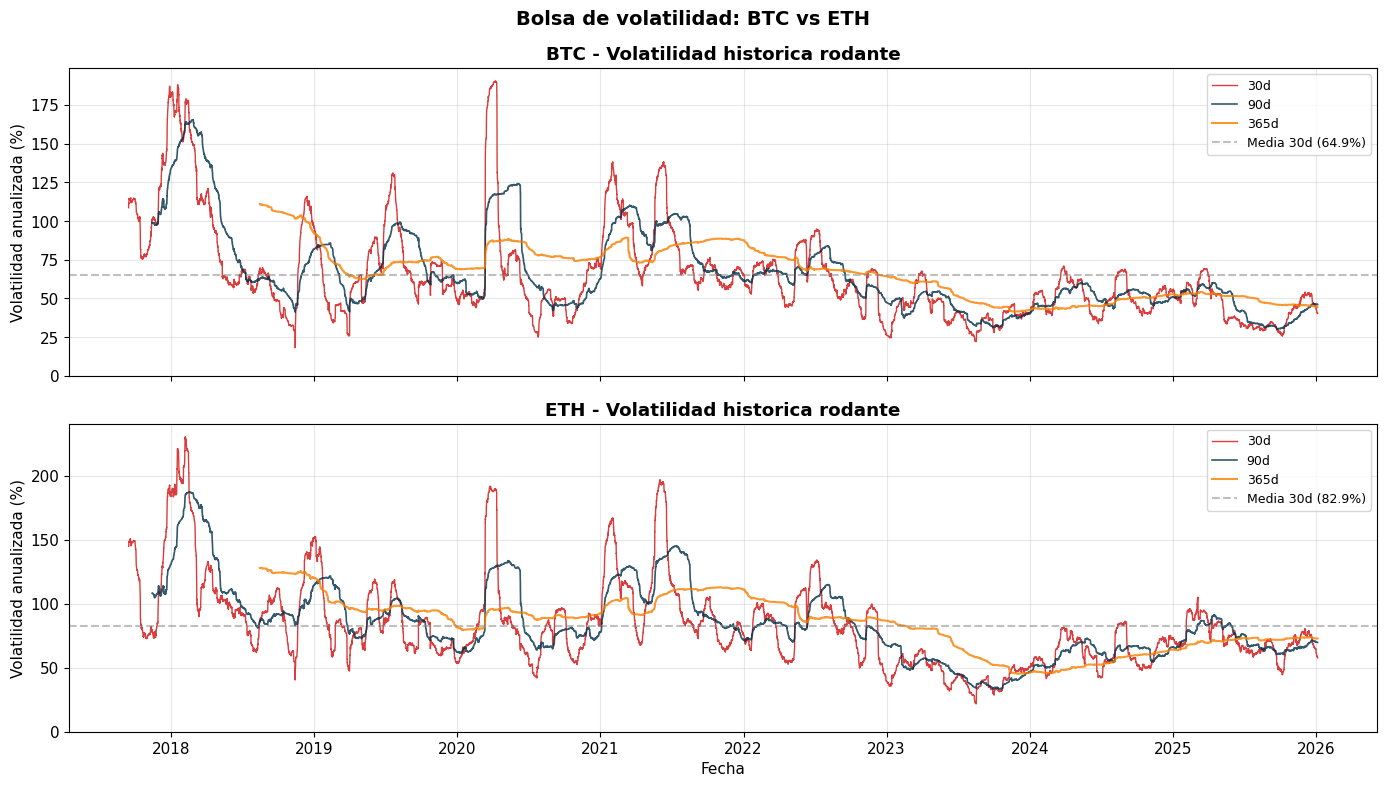

BOLSA DE VOLATILIDAD


,BTC (%),ETH (%)
Metrica,,
Vol actual (30d),40.4,57.8
Vol actual (90d),46.2,69.7
Vol actual (365d),44.5,72.7
Media historica (30d),64.9,82.9
P25 (30d),45.3,60.7
P75 (30d),71.9,95.3
Minimo (30d),18.2,21.8
Maximo (30d),190.4,230.1


BTC: Vol 30d = 40.4% -> Regimen BAJA (rango historico 18.2-190.4%)
ETH: Vol 30d = 57.8% -> Regimen BAJA (rango historico 21.8-230.1%)

ANALISIS DE BUFFER (Bolsa de Volatilidad)
Buffer minimo (% del colateral inicial) para evitar liquidacion
Horizonte: 1 anio | LTV liquidacion: 80%



Buffer P90 (%)  Buffer P95 (%)  Buffer P99 (%)
LTV Moneda                                                
10% BTC                0.0             0.0             0.0
    ETH                0.0             0.0            50.9
25% BTC                0.0             0.0            45.1
    ETH               39.4           112.5           277.2
40% BTC               32.8            53.1           132.2
    ETH              123.1           240.0           503.5
50% BTC               65.9            91.4           190.3
    ETH              178.9           324.9           654.4


Interpretacion: si el cliente provisiona al menos el buffer indicado
como colateral extra desde el inicio, evita liquidacion en >= X%
de los escenarios historicos dentro del horizonte de 1 anio.


In [3]:
# ============================================================
# BOLSA DE VOLATILIDAD
# ============================================================

# Retornos log por step (1h)
log_ret = np.log(df / df.shift(1)).dropna()

# Ventanas en steps (1h resolution)
WIN_30D  = 30  * 24   # 720 steps
WIN_90D  = 90  * 24   # 2160 steps
WIN_365D = 365 * 24   # 8760 steps

vol_data = {}
for coin in ('BTC', 'ETH'):
    r = log_ret[coin]
    vol_30  = r.rolling(WIN_30D).std()  * np.sqrt(STEPS_PER_YEAR) * 100
    vol_90  = r.rolling(WIN_90D).std()  * np.sqrt(STEPS_PER_YEAR) * 100
    vol_365 = r.rolling(WIN_365D).std() * np.sqrt(STEPS_PER_YEAR) * 100
    vol_data[coin] = {
        'vol_30': vol_30, 'vol_90': vol_90, 'vol_365': vol_365,
        'current_30':  round(float(vol_30.iloc[-1]), 1),
        'current_90':  round(float(vol_90.iloc[-1]), 1),
        'current_365': round(float(vol_365.iloc[-1]), 1),
        'mean_30':     round(float(vol_30.mean()), 1),
        'p25_30':      round(float(vol_30.quantile(0.25)), 1),
        'p75_30':      round(float(vol_30.quantile(0.75)), 1),
        'max_30':      round(float(vol_30.max()), 1),
        'min_30':      round(float(vol_30.dropna().min()), 1),
    }

# --- Grafica ---
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

for i, coin in enumerate(('BTC', 'ETH')):
    ax = axes[i]
    vd = vol_data[coin]
    ax.plot(vd['vol_30'].index,  vd['vol_30'].values,  linewidth=1.0,
            color='#d62828', alpha=0.9, label='30d')
    ax.plot(vd['vol_90'].index,  vd['vol_90'].values,  linewidth=1.2,
            color='#003049', alpha=0.8, label='90d')
    ax.plot(vd['vol_365'].index, vd['vol_365'].values, linewidth=1.5,
            color='#f77f00', alpha=0.8, label='365d')
    ax.axhline(y=vd['mean_30'], color='gray', linestyle='--', alpha=0.5,
               label=f'Media 30d ({vd["mean_30"]}%)')
    ax.set_ylabel('Volatilidad anualizada (%)')
    ax.set_title(f'{coin} - Volatilidad historica rodante', fontweight='bold')
    ax.legend(loc='upper right', fontsize=9)
    ax.set_ylim(bottom=0)

axes[1].set_xlabel('Fecha')
fig.suptitle('Bolsa de volatilidad: BTC vs ETH', fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(f'{IMG_DIR}/00_volatilidad.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Tabla resumen ---
vol_summary = pd.DataFrame({
    'Metrica': ['Vol actual (30d)', 'Vol actual (90d)', 'Vol actual (365d)',
                'Media historica (30d)', 'P25 (30d)', 'P75 (30d)',
                'Minimo (30d)', 'Maximo (30d)'],
    'BTC (%)': [vol_data['BTC']['current_30'],  vol_data['BTC']['current_90'],
                vol_data['BTC']['current_365'], vol_data['BTC']['mean_30'],
                vol_data['BTC']['p25_30'],      vol_data['BTC']['p75_30'],
                vol_data['BTC']['min_30'],      vol_data['BTC']['max_30']],
    'ETH (%)': [vol_data['ETH']['current_30'],  vol_data['ETH']['current_90'],
                vol_data['ETH']['current_365'], vol_data['ETH']['mean_30'],
                vol_data['ETH']['p25_30'],      vol_data['ETH']['p75_30'],
                vol_data['ETH']['min_30'],      vol_data['ETH']['max_30']],
}).set_index('Metrica')

print('BOLSA DE VOLATILIDAD')
print('=' * 60)
display(vol_summary)

# Regimen actual
for coin in ('BTC', 'ETH'):
    vd = vol_data[coin]
    curr = vd['current_30']
    if curr < vd['p25_30']:
        regime = 'BAJA'
    elif curr > vd['p75_30']:
        regime = 'ALTA'
    else:
        regime = 'NORMAL'
    print(f'{coin}: Vol 30d = {curr}% -> Regimen {regime} '
          f'(rango historico {vd["min_30"]}-{vd["max_30"]}%)')

# ============================================================
# ANALISIS DE BUFFER (Bolsa de Volatilidad)
# ============================================================
# Importar modulo de bolsa de volatilidad
sys.path.insert(0, '../bolsa_volatilidad')
from utils.volatility_buffer_optimizer import summarize_for_coin

# Calcular buffer requerido por LTV y moneda
# Para cada escenario LTV del modelo, cuanto colateral extra se necesita
# para sobrevivir en >=90%, >=95% y >=99% de los escenarios historicos
BUFFER_TARGETS = [0.90, 0.95, 0.99]
buffer_results = {}

for ltv in CONFIG['INIT_LTV_SCENARIOS']:
    buffer_results[ltv] = {}
    for coin in ('BTC', 'ETH'):
        coin_buffers = {}
        for q in BUFFER_TARGETS:
            summary = summarize_for_coin(
                price_df=df,
                coin=coin,
                init_ltv=ltv,
                liq_ltv=CONFIG['LIQ_LTV'],
                principal_usd=10_000,
                mode='window',
                window_minutes=STEPS_PER_YEAR,  # 1 year in steps (hourly)
                start_stride=STEPS_PER_MONTH,   # sample monthly
                target_q=q,
            )
            coin_buffers[q] = round(summary['buffer_pct_of_init_collateral@q'] * 100, 1)
        buffer_results[ltv][coin] = coin_buffers

# Tabla resumen de buffer
print('\nANALISIS DE BUFFER (Bolsa de Volatilidad)')
print('=' * 60)
print('Buffer minimo (% del colateral inicial) para evitar liquidacion')
print(f'Horizonte: 1 anio | LTV liquidacion: {CONFIG["LIQ_LTV"]*100:.0f}%')
print()

buf_rows = []
for ltv in CONFIG['INIT_LTV_SCENARIOS']:
    for coin in ('BTC', 'ETH'):
        cb = buffer_results[ltv][coin]
        buf_rows.append({
            'LTV': f'{ltv*100:.0f}%',
            'Moneda': coin,
            'Buffer P90 (%)': cb[0.90],
            'Buffer P95 (%)': cb[0.95],
            'Buffer P99 (%)': cb[0.99],
        })

buf_df = pd.DataFrame(buf_rows)
display(buf_df.set_index(['LTV', 'Moneda']))

print('\nInterpretacion: si el cliente provisiona al menos el buffer indicado')
print('como colateral extra desde el inicio, evita liquidacion en >= X%')
print('de los escenarios historicos dentro del horizonte de 1 anio.')

## 3. Motor de simulacion

Adaptacion del motor original (`legacy_code/prestamos/utils/model.py`) con las siguientes modificaciones:

1. **LTV variable**: se simula en 4 escenarios (10%, 25%, 40%, 50%)
3. **Cuota de apertura**: 2% del monto del prestamo (ingreso inmediato)
4. **Recapitalizacion**: al llegar a vencimiento, el cliente puede pagar los intereses devengados y extender el plazo por 3, 6, o 12 meses adicionales (seleccionado por el cliente). La probabilidad decae con cada recapitalizacion.
5. **Cierre al vencimiento**: si no recapitaliza, alta probabilidad de pagar el prestamo (recuperar colateral) o baja probabilidad de que se use el colateral para cubrir la deuda (sin respuesta del cliente).
6. **Montos en USD**: directamente en dolares ($100K - $20M)

### Flujo del prestamo

```
Inicio -> [Devengar interes] -> Margin Call?
  |                               |
  |                     Si: P(agregar colateral) -> Continua
  |                         P(amortizar)         -> Continua
  |                         P(ignorar)           -> Busca liquidacion
  |                               |
  +-> Vencimiento?
        |
        Si: P(recapitalizar) -> Paga intereses, extiende N meses -> Continua
            Ninguno:
              P(pagar prestamo)  -> Cierre con repago (alta prob.)
              P(usar colateral)  -> Cierre con colateral (baja prob.)
```

In [4]:
# ----- Segment Tree para busqueda eficiente O(log n) de margin calls -----

class SegmentTree:
    """Range-minimum-query tree. Build O(n), query O(log n)."""
    __slots__ = ("l", "r", "mid", "val", "ind", "L", "R")

    def __init__(self, arr, l=0, r=None):
        if r is None:
            r = len(arr)
        self.l, self.r = l, r
        self.mid = (l + r) // 2
        self.val, self.ind = arr[l], l
        if r - l > 1:
            self.L = SegmentTree(arr, l, self.mid)
            self.R = SegmentTree(arr, self.mid, r)
            if self.L.val <= self.R.val:
                self.val, self.ind = self.L.val, self.L.ind
            else:
                self.val, self.ind = self.R.val, self.R.ind
        else:
            self.L = self.R = None

    def range_min(self, ql, qr):
        if qr <= self.l or ql >= self.r:
            return float("inf"), -1
        if ql <= self.l and qr >= self.r:
            return self.val, self.ind
        lv, li = self.L.range_min(ql, qr) if self.L else (float("inf"), -1)
        rv, ri = self.R.range_min(ql, qr) if self.R else (float("inf"), -1)
        return (lv, li) if lv <= rv else (rv, ri)


def pad_loc(idx, ts):
    """Encuentra el indice mas cercano anterior o igual a ts."""
    if ts in idx:
        return idx.get_loc(ts)
    loc = idx.get_indexer([ts], method="pad")[0]
    return 0 if loc == -1 else int(loc)


print("SegmentTree y utilidades cargadas.")

SegmentTree y utilidades cargadas.


In [5]:
# ----- Clase Loan (adaptada) -----

@dataclass
class Loan:
    """Prestamo crypto-backed con Segment Tree, Markov y recapitalizacion."""
    loan_id: int
    coin: str
    principal_usd: float
    init_ltv: float
    start_idx: int
    df: pd.DataFrame
    tree: SegmentTree

    # Derivados
    mc_ltv:  float = field(default=CONFIG["MC_LTV"], init=False)
    liq_ltv: float = field(default=CONFIG["LIQ_LTV"], init=False)
    rate:    float = field(init=False)
    opening_fee: float = field(init=False)
    collateral_coin_amt: float = field(init=False)

    # Estado
    accrued_interest: float = 0.0
    interest_usd:     float = 0.0
    liq_fee:          float = 0.0
    shortfall:        float = 0.0
    amortized_usd:    float = 0.0
    status:           str = "active"
    margin_calls:     int = 0
    recapitalizations: int = 0
    end_idx:          int = field(init=False)

    def __post_init__(self):
        self.rate = CONFIG["INT_BTC"] if self.coin == "BTC" else CONFIG["INT_ETH"]
        self.opening_fee = self.principal_usd * CONFIG["OPENING_FEE_RATE"]
        self.start_ts = self.df.index[self.start_idx]
        self.start_price = float(self.df.iloc[self.start_idx][self.coin])
        self._original_principal = self.principal_usd  # guardar original
        # Colateral = principal / (LTV * precio)
        coll = (self.principal_usd / self.init_ltv) / self.start_price
        self.initial_collateral = float(coll)
        self.collateral_coin_amt = float(coll)
        self.end_idx = self.start_idx

    def run(self) -> Dict[str, Any]:
        close = self.df[self.coin].values.astype(float)
        n = len(close)
        idx = self.start_idx

        matur = pad_loc(self.df.index, self.df.index[idx] + timedelta(days=365))
        matur = min(matur, n - 1)

        while self.status == "active":
            mc_p = self.principal_usd / (self.collateral_coin_amt * self.mc_ltv)

            # Busqueda binaria + SegmentTree para siguiente margin call
            lo, hi = idx, n
            while lo + 1 < hi:
                mid = (lo + hi) // 2
                mn, _ = self.tree.range_min(idx, mid + 1)
                if mn < mc_p:
                    hi = mid
                else:
                    lo = mid

            nxt = min(v for v in [hi if hi < n else None, matur, n - 1] if v is not None)

            # Devengar interes
            steps = max(nxt - idx, 0)
            self.accrued_interest += (self.principal_usd * self.rate
                                     * (steps * minutes_per_step / MINUTES_PER_YEAR))
            idx = nxt
            self.end_idx = idx
            price = close[idx]

            # ---- VENCIMIENTO ----
            if idx >= matur:
                # 1) Recapitalizacion (nuevo)
                p_recap = CONFIG["P_RECAP_INIT"] ** (self.recapitalizations + 1)
                if random.random() < p_recap and idx + STEPS_PER_MONTH < n:
                    self.recapitalizations += 1
                    self.interest_usd += self.accrued_interest
                    self.accrued_interest = 0.0
                    ext = random.choice(CONFIG["RECAP_EXT_MONTHS"])
                    matur = min(idx + ext * STEPS_PER_MONTH, n - 1)
                    continue

                # 2) Sin recapitalizacion: pagar o liquidar con colateral
                self.interest_usd += self.accrued_interest
                self.accrued_interest = 0.0
                if random.random() < CONFIG["P_REPAY_MATURITY"]:
                    # Alta prob: cliente paga prestamo para recuperar colateral
                    self.status = "repaid_maturity"
                else:
                    # Baja prob: sin respuesta, se usa colateral para cubrir deuda
                    self.status = "settled_with_collateral"
                break

            # ---- MARGIN CALL ----
            if hi < n and idx == hi:
                self.margin_calls += 1
                p_add = CONFIG["P_ADD_INIT"] ** self.margin_calls
                p_amort = CONFIG["P_AMORT_INIT"] ** self.margin_calls
                u = random.random()

                # Agregar colateral
                if u < p_add:
                    target_val = self.principal_usd / self.init_ltv
                    curr_val = price * self.collateral_coin_amt
                    extra_usd = max(target_val - curr_val, 0.0)
                    if extra_usd > 0:
                        self.collateral_coin_amt += extra_usd / price
                    continue

                # Amortizar principal
                if u < p_add + p_amort:
                    self.interest_usd += self.accrued_interest
                    self.accrued_interest = 0.0
                    new_p = price * self.collateral_coin_amt * self.init_ltv
                    amort = max(self.principal_usd - new_p, 0.0)
                    if amort > 0:
                        self.principal_usd -= amort
                        self.amortized_usd += amort
                    continue

                # Ignorar -> buscar liquidacion
                lq_p = self.principal_usd / (self.collateral_coin_amt * self.liq_ltv)
                lo2, hi2 = idx, n
                while lo2 + 1 < hi2:
                    mid2 = (lo2 + hi2) // 2
                    mn2, _ = self.tree.range_min(idx, mid2 + 1)
                    if mn2 < lq_p:
                        hi2 = mid2
                    else:
                        lo2 = mid2
                lq = hi2 if hi2 < n else idx

                steps2 = max(lq - idx, 0)
                self.accrued_interest += (self.principal_usd * self.rate
                                         * (steps2 * minutes_per_step / MINUTES_PER_YEAR))
                idx = lq
                self.end_idx = idx
                price = close[idx]

                coll_val = price * self.collateral_coin_amt
                self.liq_fee = coll_val * CONFIG["LIQUIDATION_FEE_RATE"]
                liq_rec = max(coll_val - self.liq_fee, 0.0)
                self.shortfall = max(self.principal_usd - liq_rec, 0.0)
                self.interest_usd += self.accrued_interest
                self.accrued_interest = 0.0
                self.status = ("liquidated_full" if self.shortfall == 0
                               else "liquidated_shortfall")
                break

            # ---- FIN DE DATOS ----
            self.interest_usd += self.accrued_interest
            self.accrued_interest = 0.0
            self.status = "repaid_end_of_data"
            break

        # ---- Output ----
        self.end_price = float(close[self.end_idx])
        self.end_ts = self.df.index[self.end_idx]
        dur_steps = self.end_idx - self.start_idx
        dur_months = dur_steps * minutes_per_step / MINUTES_PER_MONTH

        gross = self.interest_usd + self.opening_fee + self.liq_fee

        return {
            "loan_id": self.loan_id,
            "coin": self.coin,
            "original_principal": round(self._original_principal, 2),
            "final_principal": round(self.principal_usd, 2),
            "init_ltv": self.init_ltv,
            "status": self.status,
            "margin_calls": self.margin_calls,
            "recapitalizations": self.recapitalizations,
            "duration_months": round(dur_months, 2),
            "interest_usd": round(self.interest_usd, 2),
            "opening_fee_usd": round(self.opening_fee, 2),
            "liq_fee_usd": round(self.liq_fee, 2),
            "shortfall_usd": round(self.shortfall, 2),
            "amortized_usd": round(self.amortized_usd, 2),
            "gross_income_usd": round(gross, 2),
            "start_price": self.start_price,
            "end_price": self.end_price,
            "collateral_init": round(self.initial_collateral, 10),
        }


print("Clase Loan cargada (con recapitalizacion y cuota de apertura).")

Clase Loan cargada (con recapitalizacion y cuota de apertura).


In [6]:
# ----- Simulacion de portafolio -----

def simulate_portfolio(price_df, init_ltv, n_loans=CONFIG["N_LOANS"]):
    """Simula n_loans prestamos (mitad BTC, mitad ETH) para un LTV dado."""
    records = []
    per_coin = n_loans // 2

    for coin in ("BTC", "ETH"):
        arr = price_df[coin].values.astype(float)
        print(f"  Construyendo SegmentTree para {coin} ({len(arr):,} nodos)...", end=" ")
        tree = SegmentTree(arr.tolist())
        print("OK")

        horizon = STEPS_PER_YEAR
        starts = list(range(max(len(arr) - horizon - 1, 1)))

        for _ in range(per_coin):
            amt = random.choices(CONFIG["LOAN_SIZES_USD"],
                                weights=CONFIG["SIZE_WEIGHTS"], k=1)[0]
            st = random.choice(starts)
            loan = Loan(len(records) + 1, coin, float(amt), init_ltv,
                        st, price_df, tree)
            records.append(loan.run())

    return pd.DataFrame(records)

print("Funcion simulate_portfolio lista.")

Funcion simulate_portfolio lista.


## 4. Simulaciones por escenario de LTV

Ejecutamos 5,000 prestamos por cada escenario de LTV (10%, 25%, 40%, 50%), con la semilla fija para reproducibilidad. Para cada escenario se reporta: tasa de liquidacion, ingreso bruto promedio, duracion promedio y numero de recapitalizaciones.

In [7]:
results = {}

for ltv in CONFIG["INIT_LTV_SCENARIOS"]:
    print(f"\n{'='*60}")
    print(f"Simulando LTV = {ltv*100:.0f}%  ({CONFIG['N_LOANS']:,} prestamos)")
    print(f"{'='*60}")
    random.seed(CONFIG["SEED"])
    np.random.seed(CONFIG["SEED"])
    results[ltv] = simulate_portfolio(df, ltv)
    r = results[ltv]

    is_liq = r.status.str.startswith("liquidated")
    print(f"  Liquidados: {is_liq.sum()} ({is_liq.mean()*100:.1f}%)")
    print(f"  Recapitalizaciones promedio: {r.recapitalizations.mean():.2f}")
    print(f"  Duracion promedio: {r.duration_months.mean():.1f} meses")
    print(f"  Principal promedio: ${r.original_principal.mean():,.0f}")
    print(f"  Ingreso bruto promedio: ${r.gross_income_usd.mean():,.0f}")

print(f"\nSimulaciones completadas: {len(results)} escenarios.")


Simulando LTV = 10%  (5,000 prestamos)
  Construyendo SegmentTree para BTC (73,480 nodos)... OK
  Construyendo SegmentTree para ETH (73,480 nodos)... OK
  Liquidados: 49 (1.0%)
  Recapitalizaciones promedio: 0.46
  Duracion promedio: 15.1 meses
  Principal promedio: $3,108,600
  Ingreso bruto promedio: $808,250

Simulando LTV = 25%  (5,000 prestamos)
  Construyendo SegmentTree para BTC (73,480 nodos)... OK
  Construyendo SegmentTree para ETH (73,480 nodos)... OK
  Liquidados: 453 (9.1%)
  Recapitalizaciones promedio: 0.42
  Duracion promedio: 14.4 meses
  Principal promedio: $3,097,400
  Ingreso bruto promedio: $787,672

Simulando LTV = 40%  (5,000 prestamos)
  Construyendo SegmentTree para BTC (73,480 nodos)... OK
  Construyendo SegmentTree para ETH (73,480 nodos)... OK
  Liquidados: 1334 (26.7%)
  Recapitalizaciones promedio: 0.33
  Duracion promedio: 12.5 meses
  Principal promedio: $3,168,400
  Ingreso bruto promedio: $747,264

Simulando LTV = 50%  (5,000 prestamos)
  Construyendo

In [8]:
# ----- Tabla resumen por escenario -----

summary_rows = []
for ltv, r in results.items():
    is_liq = r.status.str.startswith("liquidated")
    has_shortfall = r.status == "liquidated_shortfall"
    summary_rows.append({
        "LTV_inicial": f"{ltv*100:.0f}%",
        "N_prestamos": len(r),
        "Principal_prom_USD": round(r.original_principal.mean(), 0),
        "Duracion_prom_meses": round(r.duration_months.mean(), 1),
        "Tasa_liquidacion": f"{is_liq.mean()*100:.1f}%",
        "Tasa_shortfall": f"{has_shortfall.mean()*100:.1f}%",
        "Margin_calls_prom": round(r.margin_calls.mean(), 2),
        "Recapitalizaciones_prom": round(r.recapitalizations.mean(), 2),
        "Settled_collateral": f"{(r.status == 'settled_with_collateral').mean()*100:.1f}%",
        "Interes_prom_USD": round(r.interest_usd.mean(), 0),
        "Opening_fee_prom_USD": round(r.opening_fee_usd.mean(), 0),
        "Liq_fee_prom_USD": round(r.liq_fee_usd.mean(), 0),
        "Shortfall_prom_USD": round(r.shortfall_usd.mean(), 0),
        "Ingreso_bruto_prom_USD": round(r.gross_income_usd.mean(), 0),
    })

summary_df = pd.DataFrame(summary_rows).set_index("LTV_inicial")
print("\nRESUMEN POR ESCENARIO DE LTV")
print("=" * 80)
display(summary_df.T)


RESUMEN POR ESCENARIO DE LTV


LTV_inicial,10%,25%,40%,50%
N_prestamos,5000,5000,5000,5000
Principal_prom_USD,3108600.0,3097400.0,3168400.0,3066800.0
Duracion_prom_meses,15.1,14.4,12.5,10.8
Tasa_liquidacion,1.0%,9.1%,26.7%,42.7%
Tasa_shortfall,0.0%,0.0%,0.1%,0.1%
Margin_calls_prom,0.02,0.18,0.5,0.72
Recapitalizaciones_prom,0.46,0.42,0.33,0.26
Settled_collateral,9.9%,8.8%,7.2%,5.9%
Interes_prom_USD,742959.0,697838.0,603951.0,510806.0
Opening_fee_prom_USD,62172.0,61948.0,63368.0,61336.0


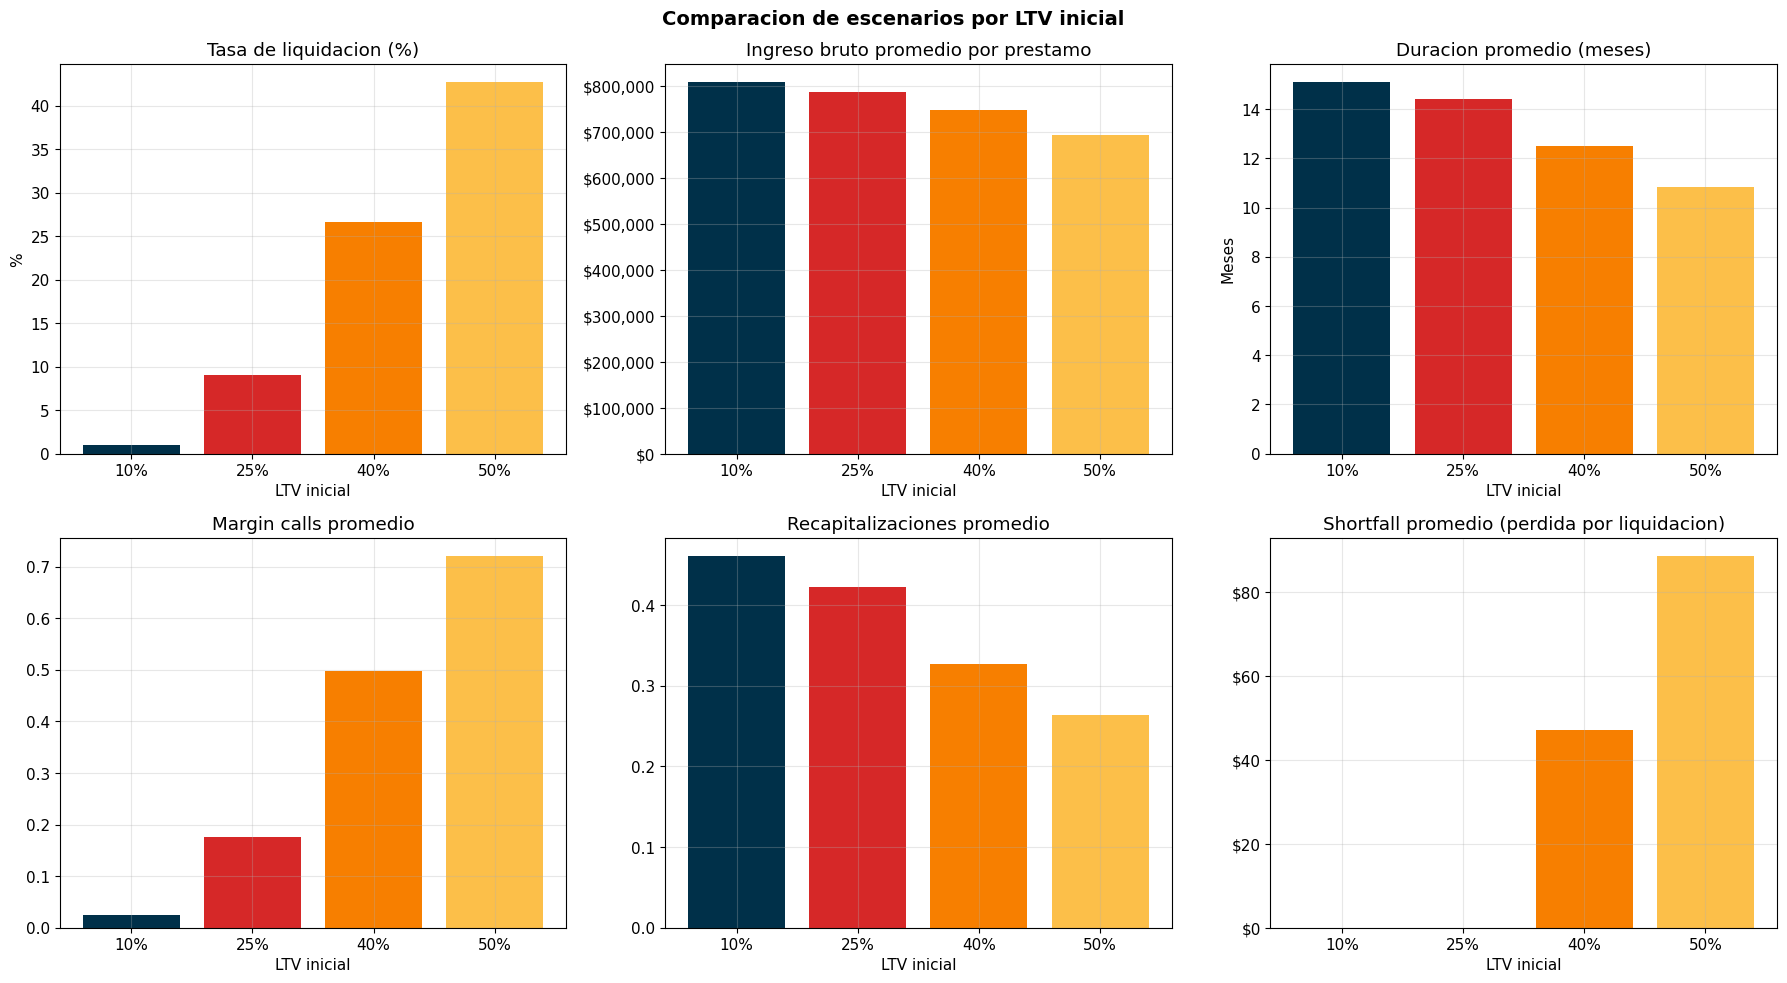

In [9]:
# ----- Graficas comparativas -----

ltv_labels = [f"{ltv*100:.0f}%" for ltv in CONFIG["INIT_LTV_SCENARIOS"]]
colors = ["#003049", "#d62828", "#f77f00", "#fcbf49"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Tasa de liquidacion
ax = axes[0, 0]
liq_rates = [results[ltv].status.str.startswith("liquidated").mean() * 100
             for ltv in CONFIG["INIT_LTV_SCENARIOS"]]
ax.bar(ltv_labels, liq_rates, color=colors)
ax.set_title("Tasa de liquidacion (%)")
ax.set_ylabel("%")

# 2. Ingreso bruto promedio
ax = axes[0, 1]
gross = [results[ltv].gross_income_usd.mean() for ltv in CONFIG["INIT_LTV_SCENARIOS"]]
ax.bar(ltv_labels, gross, color=colors)
ax.set_title("Ingreso bruto promedio por prestamo")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:,.0f}'))

# 3. Duracion promedio
ax = axes[0, 2]
durs = [results[ltv].duration_months.mean() for ltv in CONFIG["INIT_LTV_SCENARIOS"]]
ax.bar(ltv_labels, durs, color=colors)
ax.set_title("Duracion promedio (meses)")
ax.set_ylabel("Meses")

# 4. Margin calls promedio
ax = axes[1, 0]
mcs = [results[ltv].margin_calls.mean() for ltv in CONFIG["INIT_LTV_SCENARIOS"]]
ax.bar(ltv_labels, mcs, color=colors)
ax.set_title("Margin calls promedio")

# 5. Recapitalizaciones promedio
ax = axes[1, 1]
recaps = [results[ltv].recapitalizations.mean() for ltv in CONFIG["INIT_LTV_SCENARIOS"]]
ax.bar(ltv_labels, recaps, color=colors)
ax.set_title("Recapitalizaciones promedio")

# 6. Shortfall promedio
ax = axes[1, 2]
shorts = [results[ltv].shortfall_usd.mean() for ltv in CONFIG["INIT_LTV_SCENARIOS"]]
ax.bar(ltv_labels, shorts, color=colors)
ax.set_title("Shortfall promedio (perdida por liquidacion)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:,.0f}'))

for ax in axes.flat:
    ax.set_xlabel("LTV inicial")

fig.suptitle("Comparacion de escenarios por LTV inicial", fontsize=14, fontweight="bold")
plt.tight_layout()
fig.savefig(f'{IMG_DIR}/01_comparacion_ltv.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Estructura de costos

### Costos variables (por prestamo)

| Concepto | Formula | Fuente |
|---|---|---|
| Custodia BitGo | `(principal / LTV) * 0.04% * duracion_meses` | BitGo |
| Outgoing BitGo | `(principal / LTV) * 0.15% * 2 movimientos` | BitGo |
| KYC Complif | $4.45 fijo por cliente | Complif |

**Nota:** El costo de custodia es proporcional al **colateral** (= principal / LTV), no al prestamo. A menor LTV, mas colateral por dolar prestado, y por tanto mayor costo de custodia.

### Costos fijos (anuales)

| Concepto | Año 1 | Año 2+ |
|---|---|---|
| Complif Setup | $12,750 | $0 |
| Complif Mensualidades | $17,340 | $17,340 |
| Desarrollo plataforma | $18,330 | $0 |
| **Total** | **$48,420** | **$17,340** |

In [10]:
# ----- Modelo de costos -----

def compute_variable_costs(row, init_ltv):
    """Calcula costos variables por prestamo."""
    collateral_usd = row['original_principal'] / init_ltv
    dur = max(row['duration_months'], 1)

    custody = collateral_usd * CONFIG["CUSTODY_RATE_MONTHLY"] * dur
    outgoing = collateral_usd * CONFIG["OUTGOING_RATE"] * CONFIG["AVG_MOVEMENTS"]
    kyc = CONFIG["KYC_COST"]

    return pd.Series({
        'custody_cost': round(custody, 2),
        'outgoing_cost': round(outgoing, 2),
        'kyc_cost': kyc,
        'total_var_cost': round(custody + outgoing + kyc, 2),
    })


def fixed_costs(year=1):
    """Costos fijos anuales."""
    setup = CONFIG["COMPLIF_SETUP"] if year == 1 else 0
    mensual = CONFIG["COMPLIF_MONTHLY"] * 12
    dev = CONFIG["DEV_COST"] if year == 1 else 0
    total = setup + mensual + dev
    return {"complif_setup": setup, "complif_annual": mensual,
            "dev_cost": dev, "total_fixed": total}


# Aplicar costos a cada escenario
for ltv in CONFIG["INIT_LTV_SCENARIOS"]:
    r = results[ltv]
    costs = r.apply(lambda row: compute_variable_costs(row, ltv), axis=1)
    r = pd.concat([r, costs], axis=1)
    r['net_income'] = r['gross_income_usd'] - r['shortfall_usd'] - r['total_var_cost']
    results[ltv] = r

# Tabla de costos promedio por LTV
cost_rows = []
for ltv in CONFIG["INIT_LTV_SCENARIOS"]:
    r = results[ltv]
    cost_rows.append({
        "LTV": f"{ltv*100:.0f}%",
        "Custodia_prom": f"${r.custody_cost.mean():,.0f}",
        "Outgoing_prom": f"${r.outgoing_cost.mean():,.0f}",
        "KYC": f"${CONFIG['KYC_COST']:.2f}",
        "Total_var_prom": f"${r.total_var_cost.mean():,.0f}",
        "Ingreso_bruto_prom": f"${r.gross_income_usd.mean():,.0f}",
        "Shortfall_prom": f"${r.shortfall_usd.mean():,.0f}",
        "Ingreso_neto_prom": f"${r.net_income.mean():,.0f}",
    })

print("COSTOS VARIABLES PROMEDIO POR PRESTAMO")
print("=" * 80)
display(pd.DataFrame(cost_rows).set_index("LTV"))

print(f"\nCOSTOS FIJOS")
print(f"  Año 1: ${fixed_costs(1)['total_fixed']:,}")
print(f"  Año 2+: ${fixed_costs(2)['total_fixed']:,}")

COSTOS VARIABLES PROMEDIO POR PRESTAMO


,Custodia_prom,Outgoing_prom,KYC,Total_var_prom,Ingreso_bruto_prom,Shortfall_prom,Ingreso_neto_prom
LTV,,,,,,,
10%,"$188,159","$93,258",$4.45,"$281,422","$808,250",$0,"$526,828"
25%,"$71,799","$37,169",$4.45,"$108,972","$787,672",$0,"$678,699"
40%,"$39,426","$23,763",$4.45,"$63,194","$747,264",$47,"$684,023"
50%,"$26,613","$18,401",$4.45,"$45,019","$692,992",$89,"$647,885"



COSTOS FIJOS
  Año 1: $48,420
  Año 2+: $17,340


## 6. Modelo financiero: P&L y Break-Even con $20M

### Supuestos del modelo

- **Capital disponible:** $20,000,000 USD
- **Despliegue:** se asume que el capital se despliega completamente en prestamos
- **Reciclaje:** los prestamos que se repagan liberan capital para nuevos prestamos
- **Break-even:** numero minimo de prestamos para cubrir costos fijos del Año 1
- **P&L:** se calcula sobre la base de prestamos concurrentes maximos dados el capital y monto promedio

### Formula

```
Ingreso neto por prestamo = Interes + Cuota apertura + Fee liquidacion - Shortfall - Costos variables
Prestamos concurrentes max = Capital / Principal promedio
P&L anual = (Prestamos concurrentes * Ingreso neto promedio) - Costos fijos
ROI = P&L anual / Capital
Break-even (prestamos) = Costos fijos / Ingreso neto promedio
```

In [11]:
# ----- P&L y Break-Even por escenario -----

CAPITAL = CONFIG["CAPITAL_INJECTION"]
fc1 = fixed_costs(1)["total_fixed"]
fc2 = fixed_costs(2)["total_fixed"]

pnl_rows = []
for ltv in CONFIG["INIT_LTV_SCENARIOS"]:
    r = results[ltv]
    avg_principal = r.original_principal.mean()
    avg_net = r.net_income.mean()
    avg_gross = r.gross_income_usd.mean()
    avg_var = r.total_var_cost.mean()
    avg_shortfall = r.shortfall_usd.mean()
    avg_dur = r.duration_months.mean()

    # Prestamos concurrentes maximos con $20M
    max_concurrent = int(CAPITAL / avg_principal)

    # Turnover: cuantas veces se recicla el capital en un año
    # Si el prestamo dura avg_dur meses, en 12 meses se recicla 12/avg_dur veces
    turnover = 12.0 / max(avg_dur, 1)
    total_loans_year = int(max_concurrent * turnover)

    # P&L Año 1
    total_net_y1 = total_loans_year * avg_net - fc1
    roi_y1 = total_net_y1 / CAPITAL

    # P&L Año 2+
    total_net_y2 = total_loans_year * avg_net - fc2
    roi_y2 = total_net_y2 / CAPITAL

    # Break-even (prestamos para cubrir costos fijos Yr 1)
    be = math.ceil(fc1 / avg_net) if avg_net > 0 else float('inf')

    pnl_rows.append({
        "LTV": f"{ltv*100:.0f}%",
        "Principal_prom": f"${avg_principal:,.0f}",
        "Duracion_prom_meses": round(avg_dur, 1),
        "Ingreso_neto_por_prestamo": f"${avg_net:,.0f}",
        "Prestamos_concurrentes": max_concurrent,
        "Turnover_anual": round(turnover, 2),
        "Total_prestamos_año": total_loans_year,
        "P&L_Año1": f"${total_net_y1:,.0f}",
        "ROI_Año1": f"{roi_y1*100:.1f}%",
        "P&L_Año2": f"${total_net_y2:,.0f}",
        "ROI_Año2": f"{roi_y2*100:.1f}%",
        "Break_even_prestamos": be,
    })

pnl_df = pd.DataFrame(pnl_rows).set_index("LTV")
print("MODELO FINANCIERO CON INYECCION DE $20M USD")
print("=" * 80)
display(pnl_df.T)

MODELO FINANCIERO CON INYECCION DE $20M USD


LTV,10%,25%,40%,50%
Principal_prom,"$3,108,600","$3,097,400","$3,168,400","$3,066,800"
Duracion_prom_meses,15.1,14.4,12.5,10.8
Ingreso_neto_por_prestamo,"$526,828","$678,699","$684,023","$647,885"
Prestamos_concurrentes,6,6,6,6
Turnover_anual,0.8,0.83,0.96,1.11
Total_prestamos_año,4,5,5,6
P&L_Año1,"$2,058,893","$3,345,077","$3,371,695","$3,838,892"
ROI_Año1,10.3%,16.7%,16.9%,19.2%
P&L_Año2,"$2,089,973","$3,376,157","$3,402,775","$3,869,972"
ROI_Año2,10.4%,16.9%,17.0%,19.3%


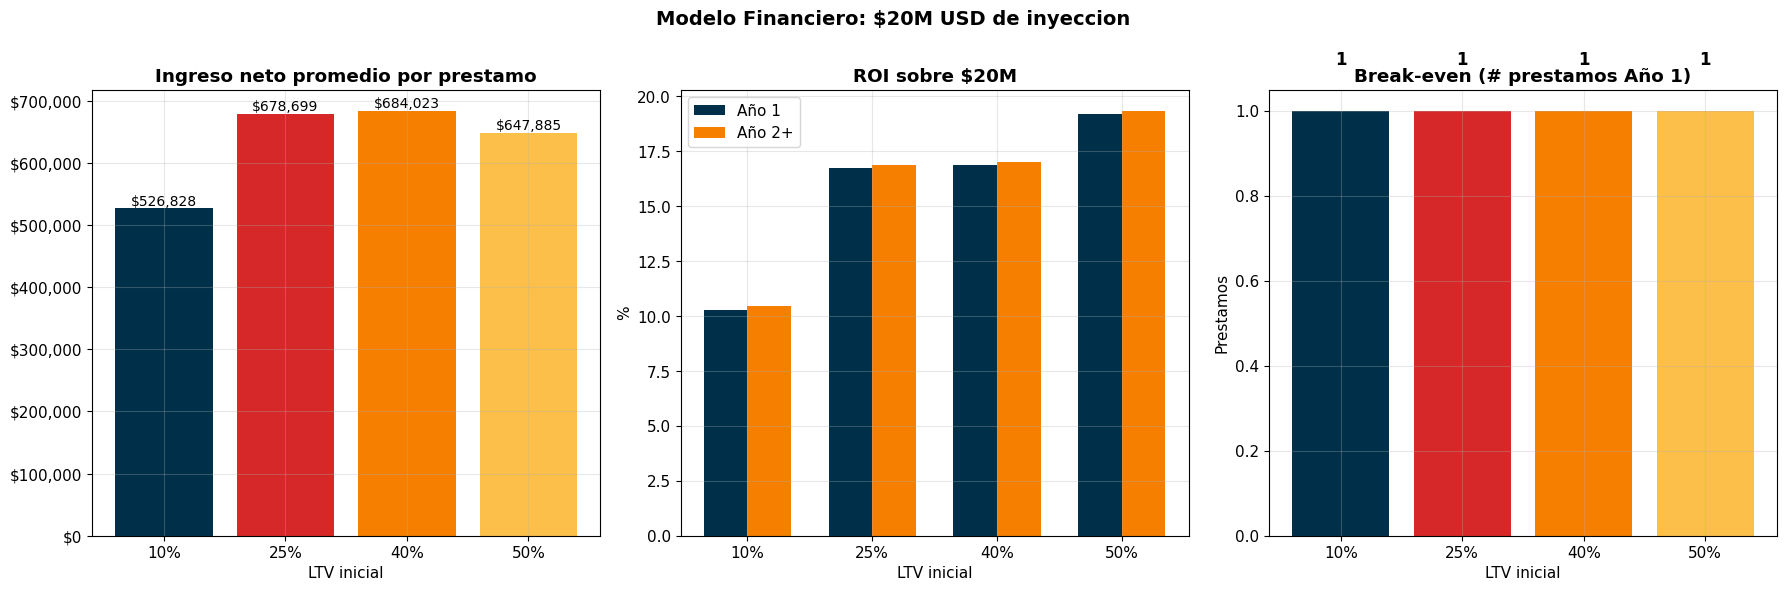

In [12]:
# ----- Visualizacion P&L y ROI -----

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Datos para graficas
ltvs = CONFIG["INIT_LTV_SCENARIOS"]
ltv_pct = [f"{x*100:.0f}%" for x in ltvs]

net_per_loan = [results[ltv].net_income.mean() for ltv in ltvs]
roi_y1 = []
roi_y2 = []
be_loans = []

for ltv in ltvs:
    r = results[ltv]
    avg_p = r.original_principal.mean()
    avg_net = r.net_income.mean()
    avg_dur = r.duration_months.mean()
    mc = int(CAPITAL / avg_p)
    tv = 12 / max(avg_dur, 1)
    tl = int(mc * tv)
    roi_y1.append((tl * avg_net - fc1) / CAPITAL * 100)
    roi_y2.append((tl * avg_net - fc2) / CAPITAL * 100)
    be_loans.append(math.ceil(fc1 / avg_net) if avg_net > 0 else 999)

# 1. Ingreso neto por prestamo
ax = axes[0]
bars = ax.bar(ltv_pct, net_per_loan, color=colors)
ax.set_title("Ingreso neto promedio por prestamo", fontweight="bold")
ax.set_xlabel("LTV inicial")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:,.0f}'))
for bar, val in zip(bars, net_per_loan):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
            f'${val:,.0f}', ha='center', va='bottom', fontsize=10)

# 2. ROI
ax = axes[1]
x = np.arange(len(ltv_pct))
w = 0.35
ax.bar(x - w/2, roi_y1, w, label="Año 1", color="#003049")
ax.bar(x + w/2, roi_y2, w, label="Año 2+", color="#f77f00")
ax.set_xticks(x)
ax.set_xticklabels(ltv_pct)
ax.set_title("ROI sobre $20M", fontweight="bold")
ax.set_xlabel("LTV inicial")
ax.set_ylabel("%")
ax.legend()

# 3. Break-even
ax = axes[2]
bars = ax.bar(ltv_pct, be_loans, color=colors)
ax.set_title("Break-even (# prestamos Año 1)", fontweight="bold")
ax.set_xlabel("LTV inicial")
ax.set_ylabel("Prestamos")
for bar, val in zip(bars, be_loans):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
            str(val), ha='center', va='bottom', fontsize=12, fontweight='bold')

fig.suptitle("Modelo Financiero: $20M USD de inyeccion", fontsize=14, fontweight="bold")
plt.tight_layout()
fig.savefig(f'{IMG_DIR}/02_pnl_roi.png', dpi=150, bbox_inches='tight')
plt.show()

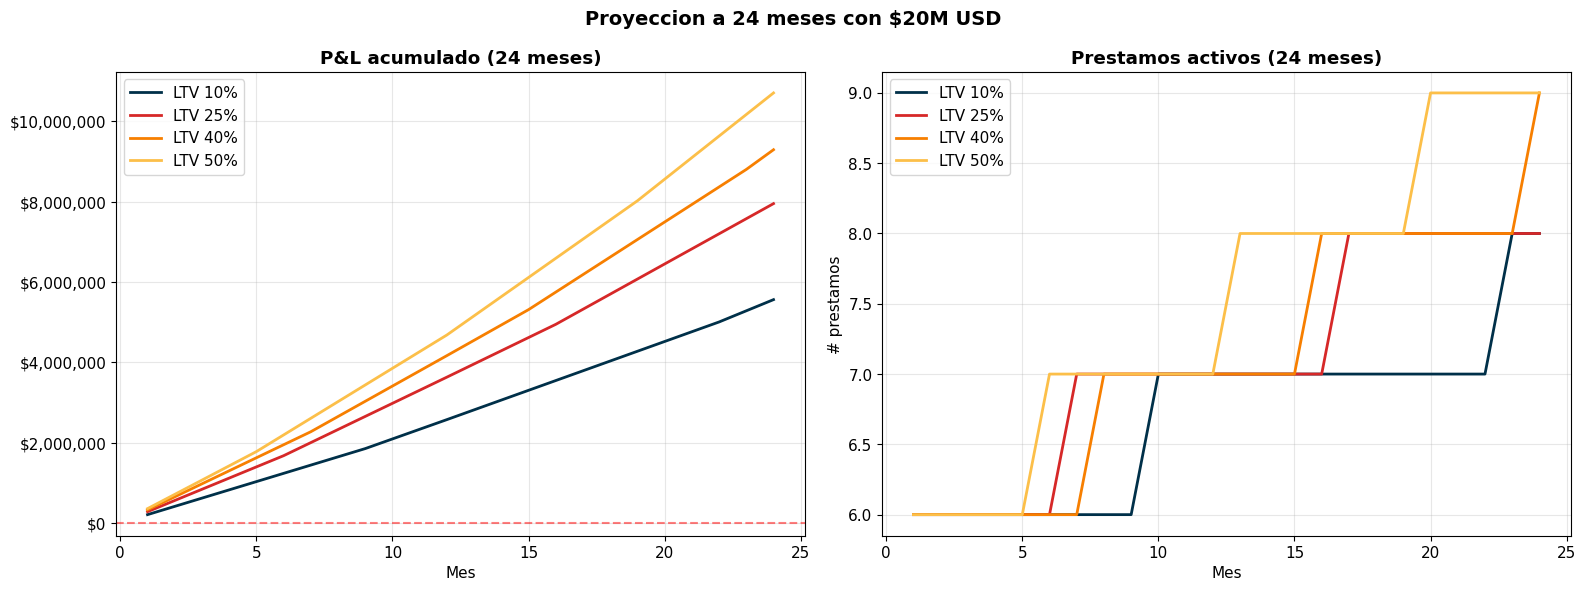

In [13]:
# ----- Proyeccion mensual de capital (mejor escenario: LTV 50%) -----

def project_monthly(ltv, capital, months=24):
    """Proyeccion simplificada mes a mes."""
    r = results[ltv]
    avg_p = r.original_principal.mean()
    avg_net = r.net_income.mean()
    avg_dur = r.duration_months.mean()
    monthly_net_per_loan = avg_net / max(avg_dur, 1)

    rows = []
    available = capital
    active_loans = 0
    cumulative_profit = 0
    fc_yr = fixed_costs(1)["total_fixed"]
    fc_monthly = fc_yr / 12

    for m in range(1, months + 1):
        if m == 13:
            fc_monthly = fixed_costs(2)["total_fixed"] / 12

        # Deploy available capital
        new_loans = int(available / avg_p)
        active_loans += new_loans
        deployed = new_loans * avg_p
        available -= deployed

        # Monthly income from active loans
        monthly_income = active_loans * monthly_net_per_loan

        # Loans maturing this month (simplified: 1/avg_dur of active loans)
        maturing = int(active_loans / max(avg_dur, 1))
        returned_capital = maturing * avg_p
        active_loans -= maturing
        available += returned_capital

        # P&L
        monthly_pnl = monthly_income - fc_monthly
        cumulative_profit += monthly_pnl
        available += monthly_income  # reinvest income

        rows.append({
            "Mes": m,
            "Prestamos_activos": active_loans,
            "Capital_disponible": round(available, 0),
            "Ingreso_mensual": round(monthly_income, 0),
            "Costos_fijos_mes": round(fc_monthly, 0),
            "P&L_mensual": round(monthly_pnl, 0),
            "P&L_acumulado": round(cumulative_profit, 0),
        })

    return pd.DataFrame(rows)


# Proyeccion para los 4 escenarios
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for i, ltv in enumerate(CONFIG["INIT_LTV_SCENARIOS"]):
    proj = project_monthly(ltv, CAPITAL, months=24)

    axes[0].plot(proj["Mes"], proj["P&L_acumulado"], label=f"LTV {ltv*100:.0f}%",
                 color=colors[i], linewidth=2)
    axes[1].plot(proj["Mes"], proj["Prestamos_activos"], label=f"LTV {ltv*100:.0f}%",
                 color=colors[i], linewidth=2)

axes[0].set_title("P&L acumulado (24 meses)", fontweight="bold")
axes[0].set_xlabel("Mes")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axes[0].legend()
axes[0].axhline(y=0, color='red', linestyle='--', alpha=0.5)

axes[1].set_title("Prestamos activos (24 meses)", fontweight="bold")
axes[1].set_xlabel("Mes")
axes[1].set_ylabel("# prestamos")
axes[1].legend()

fig.suptitle("Proyeccion a 24 meses con $20M USD", fontsize=14, fontweight="bold")
plt.tight_layout()
fig.savefig(f'{IMG_DIR}/03_proyeccion_mensual.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
# ----- Analisis de sensibilidad: cuota de apertura y tasa -----

# Impacto de la cuota de apertura en el ingreso neto
ltv_ref = 0.50  # escenario de referencia
r_ref = results[ltv_ref]

fee_rates = [0.01, 0.015, 0.02, 0.025, 0.03]
sensitivity_rows = []

for fee in fee_rates:
    # Recalcular ingreso con diferente cuota
    adj_opening = r_ref.original_principal * fee
    adj_gross = r_ref.interest_usd + adj_opening + r_ref.liq_fee_usd
    adj_net = adj_gross - r_ref.shortfall_usd - r_ref.total_var_cost
    avg_net = adj_net.mean()
    avg_p = r_ref.original_principal.mean()
    avg_dur = r_ref.duration_months.mean()
    mc = int(CAPITAL / avg_p)
    tv = 12 / max(avg_dur, 1)
    tl = int(mc * tv)
    pnl = tl * avg_net - fc1
    roi = pnl / CAPITAL * 100

    sensitivity_rows.append({
        "Cuota_apertura": f"{fee*100:.1f}%",
        "Ingreso_neto_prom": f"${avg_net:,.0f}",
        "P&L_anual": f"${pnl:,.0f}",
        "ROI": f"{roi:.1f}%",
    })

print("SENSIBILIDAD: Cuota de apertura (LTV 50%)")
print("=" * 60)
display(pd.DataFrame(sensitivity_rows).set_index("Cuota_apertura"))

# Impacto de la tasa de interes
print("\nNota: La sensibilidad sobre la tasa de interes requiere re-simulacion")
print("(la tasa afecta el devengo de intereses dentro del motor de simulacion).")
print("Los resultados mostrados asumen las tasas base: 18% BTC / 20% ETH.")

SENSIBILIDAD: Cuota de apertura (LTV 50%)


,Ingreso_neto_prom,P&L_anual,ROI
Cuota_apertura,,,
1.0%,"$617,217","$3,654,884",18.3%
1.5%,"$632,551","$3,746,888",18.7%
2.0%,"$647,885","$3,838,892",19.2%
2.5%,"$663,219","$3,930,896",19.7%
3.0%,"$678,553","$4,022,900",20.1%



Nota: La sensibilidad sobre la tasa de interes requiere re-simulacion
(la tasa afecta el devengo de intereses dentro del motor de simulacion).
Los resultados mostrados asumen las tasas base: 18% BTC / 20% ETH.


## 6.1 Reinversion de ingresos y auto-fondeo

En lugar de extraer las ganancias, se reinvierten para fondear mas prestamos. 
Se modela mes a mes hasta que las utilidades acumuladas igualen el capital inicial ($20M), 
momento en que **el costo de fondeo es cero** (capital propio generado por la operacion).

## 6.2 Modelo de intermediacion con BitGo

Escenario alternativo: en lugar de desplegar capital propio, se solicita financiamiento a BitGo 
al 10-11% anual y se presta al cliente al 18-20%. La ganancia es el **spread** menos costos operativos. 
BitGo maneja un LTV de liquidacion distinto; x2o fija el suyo mas conservador como margen de seguridad.

MODELO DE REINVERSION (auto-fondeo)
  LTV 10%: auto-fondeo en >60 meses | P&L mes 60: $17,381,906
  LTV 25%: auto-fondeo en 49 meses | P&L mes 60: $27,082,955
  LTV 40%: auto-fondeo en 44 meses | P&L mes 60: $32,928,016
  LTV 50%: auto-fondeo en 39 meses | P&L mes 60: $40,208,741


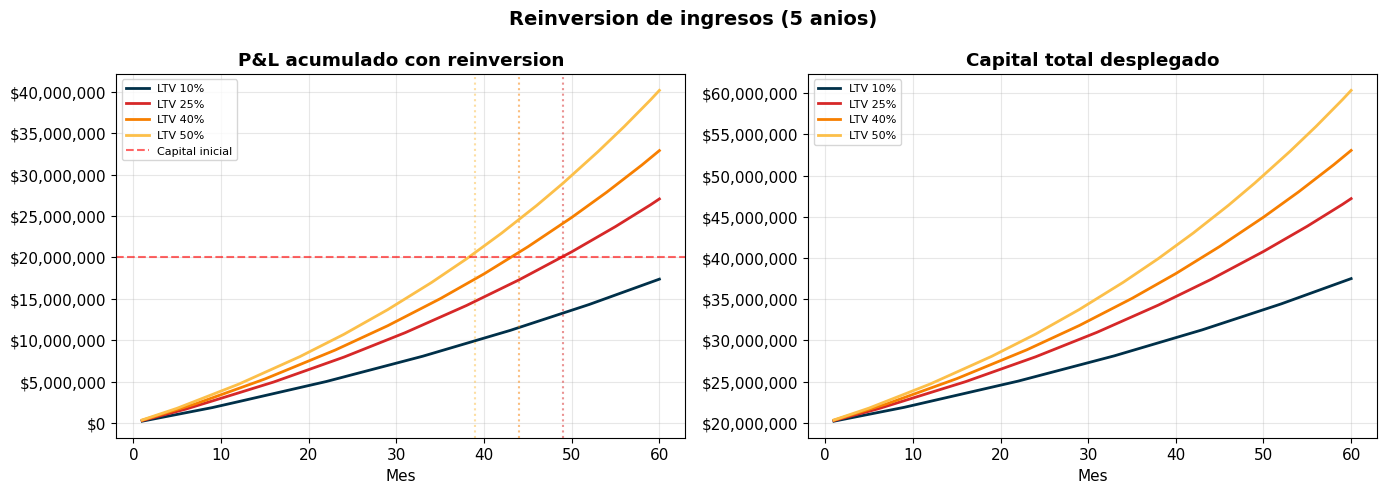


MODELO DE INTERMEDIACION CON BITGO + COBERTURA
Nuestra tasa BTC: 18.0% | ETH: 20.0%
Costo fondeo BitGo: 9.5% | Costo cobertura: 4.5%
Diferencial bruto: tasa - 14.0% = ~4.5% sobre principal
BitGo LTV liq: 85% | Nuestro LTV liq: 80% (margen: 5pp)



,Interes_prom,Costo_BitGo_prom,Costo_cobertura_prom,Spread_neto_prom,P&L_anual_spread,Capital_propio_req
LTV,,,,,,
10%,"$742,959","$372,399","$176,399","$-21,970","$-136,300",$0 (fondeo BitGo)
25%,"$697,838","$355,255","$168,279","$155,166","$727,408",$0 (fondeo BitGo)
40%,"$603,951","$311,987","$147,783","$224,252","$1,072,842",$0 (fondeo BitGo)
50%,"$510,806","$262,864","$124,515","$260,507","$1,514,620",$0 (fondeo BitGo)


In [15]:
# ============================================================
# 6.1 REINVERSION DE INGRESOS -> AUTO-FONDEO
# ============================================================

def project_reinvestment(ltv, capital, months=60):
    """Proyeccion con reinversion total de ingresos.
    Retorna DataFrame y mes de auto-fondeo (cumulative P&L >= capital)."""
    r = results[ltv]
    avg_p = r.original_principal.mean()
    avg_net = r.net_income.mean()
    avg_dur = r.duration_months.mean()
    monthly_net = avg_net / max(avg_dur, 1)

    rows = []
    available = capital
    active = 0
    cum_profit = 0
    selffund_month = None

    for m in range(1, months + 1):
        fc_m = fixed_costs(1)['total_fixed'] / 12 if m <= 12 else fixed_costs(2)['total_fixed'] / 12

        # Desplegar capital disponible
        new = int(available / avg_p)
        active += new
        available -= new * avg_p

        # Ingreso mensual
        income = active * monthly_net

        # Vencimientos
        maturing = int(active / max(avg_dur, 1))
        available += maturing * avg_p
        active -= maturing

        # P&L
        pnl = income - fc_m
        cum_profit += pnl
        available += income  # reinvertir TODO

        if selffund_month is None and cum_profit >= capital:
            selffund_month = m

        rows.append({
            'Mes': m,
            'Prestamos_activos': active,
            'Capital_total': round(available + active * avg_p),
            'P&L_acumulado': round(cum_profit),
        })

    return pd.DataFrame(rows), selffund_month

# Ejecutar para cada LTV
print('MODELO DE REINVERSION (auto-fondeo)')
print('=' * 60)

reinvest_data = {}
for ltv in CONFIG['INIT_LTV_SCENARIOS']:
    proj, sf_month = project_reinvestment(ltv, CAPITAL, months=60)
    reinvest_data[ltv] = {'proj': proj, 'selffund_month': sf_month}
    label = f'{sf_month} meses' if sf_month else '>60 meses'
    print(f'  LTV {ltv*100:.0f}%: auto-fondeo en {label} '
          f'| P&L mes 60: ${proj.iloc[-1]["P&L_acumulado"]:,.0f}')

# Grafica
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, ltv in enumerate(CONFIG['INIT_LTV_SCENARIOS']):
    proj = reinvest_data[ltv]['proj']
    sf = reinvest_data[ltv]['selffund_month']
    c = colors[i]
    axes[0].plot(proj['Mes'], proj['P&L_acumulado'], color=c, linewidth=2,
                 label=f'LTV {ltv*100:.0f}%')
    axes[1].plot(proj['Mes'], proj['Capital_total'], color=c, linewidth=2,
                 label=f'LTV {ltv*100:.0f}%')
    if sf:
        axes[0].axvline(x=sf, color=c, linestyle=':', alpha=0.5)

axes[0].axhline(y=CAPITAL, color='red', linestyle='--', alpha=0.6, label='Capital inicial')
axes[0].set_title('P&L acumulado con reinversion', fontweight='bold')
axes[0].set_xlabel('Mes')
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axes[0].legend(fontsize=8)

axes[1].set_title('Capital total desplegado', fontweight='bold')
axes[1].set_xlabel('Mes')
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axes[1].legend(fontsize=8)

fig.suptitle('Reinversion de ingresos (5 anios)', fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(f'{IMG_DIR}/05_reinversion.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================
# 6.2 MODELO DE INTERMEDIACION CON BITGO + COBERTURA
# ============================================================

BITGO_RATE = 0.095  # Costo de fondeo BitGo: 9.5% anual
HEDGE_RATE = 0.045  # Costo de cobertura (volatility / liquidation insurance): 4.5% anual
BITGO_LIQ_LTV = 0.85
OUR_LIQ_LTV = CONFIG['LIQ_LTV']
MARGEN_SEGURIDAD = BITGO_LIQ_LTV - OUR_LIQ_LTV

print(f'\n{"="*60}')
print('MODELO DE INTERMEDIACION CON BITGO + COBERTURA')
print(f'{"="*60}')
print(f'Nuestra tasa BTC: {CONFIG["INT_BTC"]*100:.1f}% | ETH: {CONFIG["INT_ETH"]*100:.1f}%')
print(f'Costo fondeo BitGo: {BITGO_RATE*100:.1f}% | Costo cobertura: {HEDGE_RATE*100:.1f}%')
print(f'Diferencial bruto: tasa - {(BITGO_RATE+HEDGE_RATE)*100:.1f}% = ~{(0.185-(BITGO_RATE+HEDGE_RATE))*100:.1f}% sobre principal')
print(f'BitGo LTV liq: {BITGO_LIQ_LTV*100:.0f}% | Nuestro LTV liq: {OUR_LIQ_LTV*100:.0f}% (margen: {MARGEN_SEGURIDAD*100:.0f}pp)')
print()

spread_rows = []
for ltv in CONFIG['INIT_LTV_SCENARIOS']:
    r = results[ltv]
    # Costo de fondeo + cobertura: ambos proporcionales a principal * duracion
    bitgo_cost = r.original_principal * BITGO_RATE * (r.duration_months / 12)
    hedge_cost = r.original_principal * HEDGE_RATE * (r.duration_months / 12)
    funding_total = bitgo_cost + hedge_cost

    # Spread income = nuestro interes - fondeo total + fees
    spread_gross = r.interest_usd - funding_total + r.opening_fee_usd + r.liq_fee_usd
    spread_net = spread_gross - r.shortfall_usd - r.total_var_cost

    avg_p = r.original_principal.mean()
    avg_dur = r.duration_months.mean()
    mc = int(CAPITAL / avg_p)
    tv = 12 / max(avg_dur, 1)
    tl = int(mc * tv)
    total_spread = tl * spread_net.mean() - fc1

    spread_rows.append({
        'LTV': f'{ltv*100:.0f}%',
        'Interes_prom': f'${r.interest_usd.mean():,.0f}',
        'Costo_BitGo_prom': f'${bitgo_cost.mean():,.0f}',
        'Costo_cobertura_prom': f'${hedge_cost.mean():,.0f}',
        'Spread_neto_prom': f'${spread_net.mean():,.0f}',
        'P&L_anual_spread': f'${total_spread:,.0f}',
        'Capital_propio_req': '$0 (fondeo BitGo)',
    })

spread_df = pd.DataFrame(spread_rows).set_index('LTV')
display(spread_df)

PARAMETROS DEL CROSSOVER (LTV 40%)
Prestamos al año:           5
Capital propio comprometido: $20,000,000
Tasa alternativa para capital: 10.0% anual (CETES como benchmark)

CAPITAL PROPIO:
  Ingreso neto/prestamo: $684,023
  P&L mensual:           $280,975
  P&L anual:             $3,371,695
  ROI anual:             16.9%

BITGO (capital propio = $0):
  Spread neto/prestamo:  $224,252
  P&L mensual:           $89,404
  P&L anual:             $1,072,842

CROSSOVER ANALYSIS (60 meses, alt rate 10%)
Capital propio supera a BitGo en el MES 1
  Riqueza adicional en mes 1: $32,088
Mes 60 — Capital propio: $16,858,476  |  BitGo: $17,574,411  |  diff: $-715,935

SENSIBILIDAD: mes de crossover segun tasa alternativa
------------------------------------------------------------
  Alt   0.0% -> Mes 1
  Alt   5.0% -> Mes 1
  Alt   8.0% -> Mes 1
  Alt  10.0% -> Mes 1
  Alt  12.0% -> Mes 1
  Alt  15.0% -> >60 meses


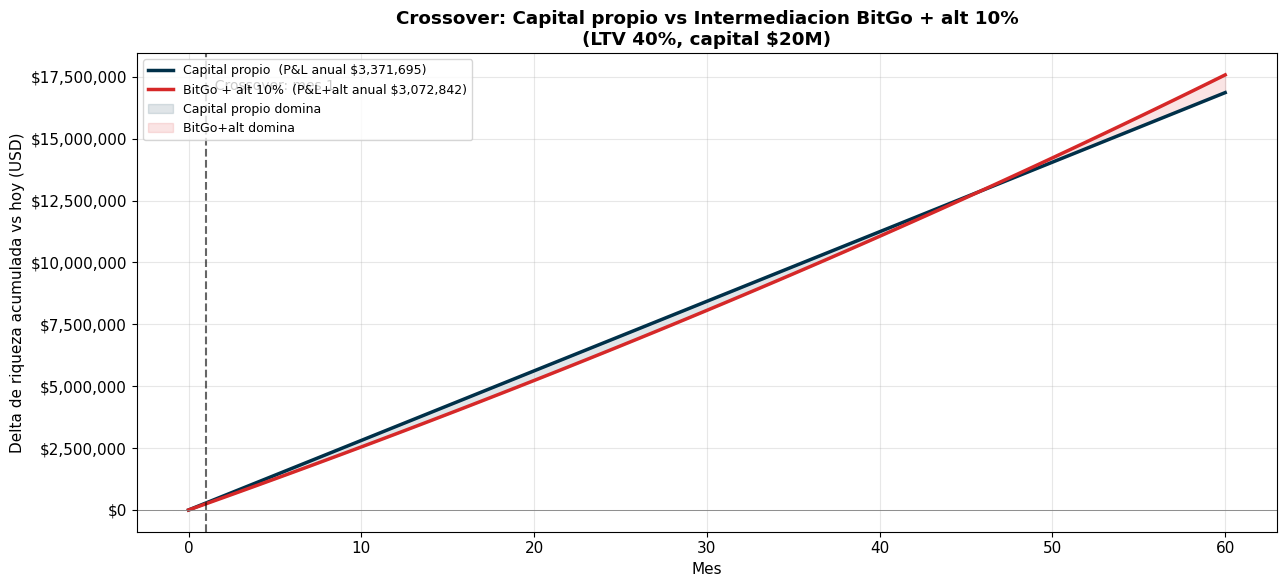


VISTA DE CONTADOR — ESTADO DE RESULTADOS ANUAL
  CAPITAL PROPIO    BITGO (intermediacion)
Ingresos anuales:   $     3,736,320    $     3,736,320
  (-) Fondeo BitGo  $0                $     2,298,853
  (-) Var costos    $       316,205    $       316,205
  Margen bruto      $     3,420,115    $     1,121,262
  (-) Costos fijos  $        48,420    $        48,420
Utilidad anual:     $     3,371,695    $     1,072,842
Capital comprometido: $  20,000,000    $0
ROI sobre capital:            16.9%    infinito


In [16]:
# ============================================================
# 6.3 CROSSOVER: CAPITAL PROPIO vs INTERMEDIACION BITGO
# ============================================================
# Comparativa directa de utilidad acumulada mes a mes en ambos modelos.
# Pregunta: a cuantos meses el modelo con capital propio ($20M tied up) genera
# MAS utilidad acumulada que el modelo BitGo (capital propio = $0)?

CROSSOVER_LTV = 0.40
CROSSOVER_MONTHS = 60
ALT_RATE_ANNUAL = 0.10  # tasa alternativa para los $20M si NO los inviertes en prestamos
                        # (CETES MX ~10% anual). Si fuera 0%, capital propio domina trivialmente.

r_x = results[CROSSOVER_LTV]
avg_p_x   = r_x.original_principal.mean()
avg_dur_x = r_x.duration_months.mean()
own_net_per_loan_x = r_x.net_income.mean()

# Ingreso neto BitGo por prestamo (mismas operaciones, distinta fuente de fondeo)
bitgo_cost_x = (r_x.original_principal * BITGO_RATE * (r_x.duration_months / 12))
hedge_cost_x = (r_x.original_principal * HEDGE_RATE * (r_x.duration_months / 12))
spread_net_per_loan_x = (
    r_x.interest_usd - bitgo_cost_x - hedge_cost_x
    + r_x.opening_fee_usd + r_x.liq_fee_usd
    - r_x.shortfall_usd - r_x.total_var_cost
).mean()

mc_x = int(CAPITAL / avg_p_x)
loans_per_year_x = int(mc_x * 12 / max(avg_dur_x, 1))
loans_per_month = loans_per_year_x / 12

own_monthly_pnl   = (own_net_per_loan_x   * loans_per_month) - (fixed_costs(1)['total_fixed'] / 12)
bitgo_monthly_pnl = (spread_net_per_loan_x * loans_per_month) - (fixed_costs(1)['total_fixed'] / 12)

print(f'PARAMETROS DEL CROSSOVER (LTV {CROSSOVER_LTV*100:.0f}%)')
print('=' * 60)
print(f'Prestamos al año:           {loans_per_year_x}')
print(f'Capital propio comprometido: ${CAPITAL:,.0f}')
print(f'Tasa alternativa para capital: {ALT_RATE_ANNUAL*100:.1f}% anual (CETES como benchmark)')
print()
print(f'CAPITAL PROPIO:')
print(f'  Ingreso neto/prestamo: ${own_net_per_loan_x:,.0f}')
print(f'  P&L mensual:           ${own_monthly_pnl:,.0f}')
print(f'  P&L anual:             ${own_monthly_pnl*12:,.0f}')
print(f'  ROI anual:             {own_monthly_pnl*12/CAPITAL*100:.1f}%')
print()
print(f'BITGO (capital propio = $0):')
print(f'  Spread neto/prestamo:  ${spread_net_per_loan_x:,.0f}')
print(f'  P&L mensual:           ${bitgo_monthly_pnl:,.0f}')
print(f'  P&L anual:             ${bitgo_monthly_pnl*12:,.0f}')
print()

# Trayectorias de utilidad acumulada (riqueza neta del inversor)
# Capital propio: $0 inicial (los $20M estan deployed en prestamos, mismo valor) + cum_pnl
# BitGo: $20M libre creciendo a ALT_RATE_ANNUAL (no necesitas comprometer capital) + cum_pnl
months = np.arange(0, CROSSOVER_MONTHS + 1)
own_wealth   = own_monthly_pnl * months  # delta de riqueza vs hoy
alt_monthly_factor = (1 + ALT_RATE_ANNUAL) ** (1/12) - 1
bitgo_wealth = bitgo_monthly_pnl * months + CAPITAL * ((1 + alt_monthly_factor) ** months - 1)

# Mes de crossover
diff = own_wealth - bitgo_wealth
crossover_month = None
for m in range(1, len(diff)):
    if diff[m] > 0 and (crossover_month is None):
        crossover_month = m
        break

print(f'CROSSOVER ANALYSIS (60 meses, alt rate {ALT_RATE_ANNUAL*100:.0f}%)')
print('=' * 60)
if crossover_month:
    print(f'Capital propio supera a BitGo en el MES {crossover_month}')
    print(f'  Riqueza adicional en mes {crossover_month}: ${diff[crossover_month]:,.0f}')
else:
    print(f'BitGo (con alt rate {ALT_RATE_ANNUAL*100:.0f}%) supera a capital propio en los 60 meses analizados')
print(f'Mes 60 — Capital propio: ${own_wealth[-1]:,.0f}  |  BitGo: ${bitgo_wealth[-1]:,.0f}  |  diff: ${diff[-1]:,.0f}')

# Sensibilidad a la tasa alternativa
print()
print('SENSIBILIDAD: mes de crossover segun tasa alternativa')
print('-' * 60)
crossover_sens = []
for alt in [0.0, 0.05, 0.08, 0.10, 0.12, 0.15]:
    alt_mf = (1 + alt) ** (1/12) - 1
    bg = bitgo_monthly_pnl * months + CAPITAL * ((1 + alt_mf) ** months - 1)
    gap = own_wealth - bg
    cm = next((m for m in range(1, len(gap)) if gap[m] > 0), None)
    cm_label = f'Mes {cm}' if cm else '>60 meses'
    crossover_sens.append({'alt_rate': alt, 'crossover_month': cm, 'label': cm_label})
    print(f'  Alt {alt*100:5.1f}% -> {cm_label}')

# --- Grafica del crossover ---
fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(months, own_wealth, color='#003049', linewidth=2.5,
        label=f'Capital propio  (P&L anual ${own_monthly_pnl*12:,.0f})')
ax.plot(months, bitgo_wealth, color='#d62828', linewidth=2.5,
        label=f'BitGo + alt {ALT_RATE_ANNUAL*100:.0f}%  (P&L+alt anual ${bitgo_wealth[12]:,.0f})')
ax.fill_between(months, own_wealth, bitgo_wealth,
                where=(own_wealth >= bitgo_wealth), color='#003049', alpha=0.12,
                label='Capital propio domina')
ax.fill_between(months, own_wealth, bitgo_wealth,
                where=(own_wealth < bitgo_wealth), color='#d62828', alpha=0.12,
                label='BitGo+alt domina')
if crossover_month:
    ax.axvline(x=crossover_month, color='black', linestyle='--', alpha=0.6)
    ax.text(crossover_month, ax.get_ylim()[1]*0.92,
            f'  Crossover: mes {crossover_month}', fontsize=10)
ax.axhline(y=0, color='gray', linewidth=0.6)
ax.set_xlabel('Mes')
ax.set_ylabel('Delta de riqueza acumulada vs hoy (USD)')
ax.set_title(f'Crossover: Capital propio vs Intermediacion BitGo + alt {ALT_RATE_ANNUAL*100:.0f}%\n'
             f'(LTV {CROSSOVER_LTV*100:.0f}%, capital ${CAPITAL/1e6:.0f}M)',
             fontweight='bold')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout()
fig.savefig(f'{IMG_DIR}/07_crossover_bitgo.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================
# 6.4 VISTA DE CONTADOR — ESTADO DE RESULTADOS COMPARATIVO
# ============================================================
# Tabla side-by-side legible para contadores: ingresos, costos y utilidad
# por modelo, sobre base anual.

WEIGHTED_RATE = (CONFIG['INT_BTC'] + CONFIG['INT_ETH']) / 2  # ~19%
print(f'\nVISTA DE CONTADOR — ESTADO DE RESULTADOS ANUAL')
print('=' * 60)

# Datos por prestamo promedio (LTV 40%)
interest_per_loan = r_x.interest_usd.mean()
opening_per_loan  = r_x.opening_fee_usd.mean()
liqfee_per_loan   = r_x.liq_fee_usd.mean()
custody_per_loan  = r_x.custody_cost.mean()
outgoing_per_loan = r_x.outgoing_cost.mean()
kyc_per_loan      = r_x.kyc_cost.mean()
shortfall_per_loan = r_x.shortfall_usd.mean()
bitgo_cost_per_loan = bitgo_cost_x.mean()
hedge_cost_per_loan = hedge_cost_x.mean()

N = loans_per_year_x  # prestamos al año

accountant_view = {
    'capital_required': CAPITAL,
    'loans_per_year': N,
    'avg_principal': avg_p_x,
    'avg_duration_months': avg_dur_x,
    'weighted_rate': WEIGHTED_RATE,
    'bitgo_rate': BITGO_RATE,
    'hedge_rate': HEDGE_RATE,
    'fc1': fc1,
    'fc2': fc2,

    # Por prestamo promedio
    'interest_per_loan': interest_per_loan,
    'opening_per_loan': opening_per_loan,
    'liqfee_per_loan': liqfee_per_loan,
    'custody_per_loan': custody_per_loan,
    'outgoing_per_loan': outgoing_per_loan,
    'kyc_per_loan': kyc_per_loan,
    'shortfall_per_loan': shortfall_per_loan,
    'bitgo_cost_per_loan': bitgo_cost_per_loan,
    'hedge_cost_per_loan': hedge_cost_per_loan,

    # Anuales
    'own_monthly_pnl': own_monthly_pnl,
    'bitgo_monthly_pnl': bitgo_monthly_pnl,
    'crossover_month': crossover_month,
    'crossover_sens': crossover_sens,
    'alt_rate_annual': ALT_RATE_ANNUAL,
}

# Estado de resultados ANUAL — Capital propio
own_revenue_annual = N * (interest_per_loan + opening_per_loan + liqfee_per_loan)
own_var_costs_annual = N * (custody_per_loan + outgoing_per_loan + kyc_per_loan + shortfall_per_loan)
own_gross_margin = own_revenue_annual - own_var_costs_annual
own_net_pnl = own_gross_margin - fc1

# Estado de resultados ANUAL — BitGo
bg_revenue_annual = N * (interest_per_loan + opening_per_loan + liqfee_per_loan)
bg_funding_cost = N * (bitgo_cost_per_loan + hedge_cost_per_loan)
bg_var_costs_annual = N * (custody_per_loan + outgoing_per_loan + kyc_per_loan + shortfall_per_loan)
bg_gross_margin = bg_revenue_annual - bg_funding_cost - bg_var_costs_annual
bg_net_pnl = bg_gross_margin - fc1

print(f'  CAPITAL PROPIO    BITGO (intermediacion)')
print(f'Ingresos anuales:   ${own_revenue_annual:>14,.0f}    ${bg_revenue_annual:>14,.0f}')
print(f'  (-) Fondeo BitGo  $0                ${bg_funding_cost:>14,.0f}')
print(f'  (-) Var costos    ${own_var_costs_annual:>14,.0f}    ${bg_var_costs_annual:>14,.0f}')
print(f'  Margen bruto      ${own_gross_margin:>14,.0f}    ${bg_gross_margin:>14,.0f}')
print(f'  (-) Costos fijos  ${fc1:>14,.0f}    ${fc1:>14,.0f}')
print(f'Utilidad anual:     ${own_net_pnl:>14,.0f}    ${bg_net_pnl:>14,.0f}')
print(f'Capital comprometido: ${CAPITAL:>12,.0f}    $0')
print(f'ROI sobre capital:   {own_net_pnl/CAPITAL*100:>13.1f}%    infinito')

accountant_view.update({
    'own_revenue_annual': own_revenue_annual,
    'own_var_costs_annual': own_var_costs_annual,
    'own_gross_margin': own_gross_margin,
    'own_net_pnl': own_net_pnl,
    'bg_revenue_annual': bg_revenue_annual,
    'bg_funding_cost': bg_funding_cost,
    'bg_var_costs_annual': bg_var_costs_annual,
    'bg_gross_margin': bg_gross_margin,
    'bg_net_pnl': bg_net_pnl,
})


## 7. Prediccion de precios futuros (Monte Carlo Bootstrap)

Usando el motor de simulacion Monte Carlo con Bootstrap-KDE (`legacy_code/precios_futuros/utils/bootstrap_mc.py`), generamos 2,000 trayectorias de precio futuro para BTC y ETH con horizonte de 365 dias. El modelo:

1. Toma los retornos historicos paso a paso de la serie resampleada
2. Aplica Bootstrap con suavizado KDE (Kernel Density Estimation) usando regla de Silverman
3. Genera trayectorias simuladas multiplicando factores de retorno
4. Resume las probabilidades de caida significativa del precio

Estas metricas alimentan directamente la evaluacion de riesgo de margin call y liquidacion.

In [17]:
# Agregar path para modulo de prediccion
sys.path.insert(0, '../precios_futuros')
from utils.bootstrap_mc import MonteCarloPriceSimulator, infer_horizon_steps

PRED_HORIZON_DAYS = 365
PRED_N_SIMS = 2000
pred_summaries = {}

for coin in ('BTC', 'ETH'):
    print(f'\n{"="*60}')
    print(f'Prediccion {coin} - {PRED_N_SIMS} sims, horizonte {PRED_HORIZON_DAYS} dias')
    print(f'{"="*60}')

    series = df[coin].dropna().astype(float)
    horizon_steps = infer_horizon_steps(series, PRED_HORIZON_DAYS)
    mc = MonteCarloPriceSimulator(series, n_sims=PRED_N_SIMS)
    price_paths = mc.simulate_paths(horizon_steps)
    summary = mc.summarize_risk(price_paths)
    pred_summaries[coin] = summary

    for k, v in summary.items():
        if 'price' in k:
            print(f'  {k}: ${v:,.2f}')
        else:
            print(f'  {k}: {v*100:.1f}%')

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Trayectorias simuladas
    ax = axes[0]
    for i in range(min(100, price_paths.shape[1])):
        s = price_paths.iloc[:, i]
        c = '#006d77' if s.iloc[-1] >= s.iloc[0] else '#e29578'
        ax.plot(s.values, alpha=0.3, linewidth=0.8, color=c)
    ax.set_title(f'Trayectorias simuladas {coin}')
    ax.set_xlabel('Step futuro')
    ax.set_ylabel('Precio')

    # 2. Banda de percentiles
    ax = axes[1]
    desc = price_paths.T.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])
    steps = np.arange(len(desc.loc['50%']))
    ax.fill_between(steps, desc.loc['5%'].values, desc.loc['95%'].values,
                    alpha=0.15, color='#003049', label='P5-P95')
    ax.fill_between(steps, desc.loc['25%'].values, desc.loc['75%'].values,
                    alpha=0.3, color='#003049', label='P25-P75')
    ax.plot(steps, desc.loc['50%'].values, color='#d62828', linewidth=2, label='Mediana')
    ax.set_title(f'Banda de percentiles {coin}')
    ax.set_xlabel('Step futuro')
    ax.set_ylabel('Precio')
    ax.legend()

    # 3. Distribucion terminal
    ax = axes[2]
    f0 = price_paths.iloc[0, :].values
    fN = price_paths.iloc[-1, :].values
    ret = (fN / f0 - 1.0) * 100
    ax.hist(ret, bins=50, alpha=0.8, edgecolor='k', color='#fcbf49')
    ax.axvline(x=0, color='red', linestyle='--', alpha=0.7)
    ax.axvline(x=-20, color='darkred', linestyle=':', alpha=0.7, label='Caida 20%')
    ax.axvline(x=-40, color='black', linestyle=':', alpha=0.7, label='Caida 40%')
    ax.set_title(f'Distribucion retorno final {coin}')
    ax.set_xlabel('Retorno (%)')
    ax.set_ylabel('Frecuencia')
    ax.legend()

    fig.suptitle(f'Prediccion {coin} - Horizonte {PRED_HORIZON_DAYS} dias',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    fig.savefig(f'{IMG_DIR}/04_prediccion_{coin.lower()}.png', dpi=150,
                bbox_inches='tight')
    plt.show()

# Tabla resumen de prediccion
print(f'\n{"="*60}')
print('RESUMEN DE PREDICCION DE PRECIOS')
print(f'{"="*60}')
pred_table = pd.DataFrame({
    'Metrica': ['Precio inicial', 'Precio mediano final', 'Percentil 5% final',
                'P(caida >=20%)', 'P(caida >=40%)'],
    'BTC': [f"${pred_summaries['BTC']['start_price']:,.2f}",
            f"${pred_summaries['BTC']['median_final_price']:,.2f}",
            f"${pred_summaries['BTC']['p05_final_price']:,.2f}",
            f"{pred_summaries['BTC']['prob_drop_20pct_or_more']*100:.1f}%",
            f"{pred_summaries['BTC']['prob_drop_40pct_or_more']*100:.1f}%"],
    'ETH': [f"${pred_summaries['ETH']['start_price']:,.2f}",
            f"${pred_summaries['ETH']['median_final_price']:,.2f}",
            f"${pred_summaries['ETH']['p05_final_price']:,.2f}",
            f"{pred_summaries['ETH']['prob_drop_20pct_or_more']*100:.1f}%",
            f"{pred_summaries['ETH']['prob_drop_40pct_or_more']*100:.1f}%"],
}).set_index('Metrica')
display(pred_table)


Prediccion BTC - 2000 sims, horizonte 365 dias


IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

## 8. Conclusiones

### Hallazgos principales

1. **LTV y riesgo de liquidacion**: Como se esperaba, a menor LTV inicial, menor probabilidad de liquidacion. Con LTV 10%, las liquidaciones son practicamente nulas (el precio tendria que caer >86% para un margin call). Con LTV 50%, la tasa de liquidacion refleja la volatilidad real del mercado crypto.

2. **Trade-off custodia vs. riesgo**: Menores LTVs implican mayor colateral por dolar prestado, lo que incrementa los costos de custodia de BitGo proporcionalmente. Este es el trade-off fundamental del modelo.

3. **Recapitalizacion**: La mecanica de recapitalizacion (pagar intereses y extender plazo) genera:
   - Mayor duracion promedio de los prestamos
   - Cobro de intereses durante la vida del prestamo (no solo al final)
   - Mayor ingreso total por prestamo

4. **Cierre al vencimiento**: Si el cliente no recapitaliza, tiene alta probabilidad de pagar el prestamo (para no perder su colateral). En el caso poco probable de no respuesta, el colateral se usa para cubrir la deuda — un escenario raro dado que clientes que han agregado colateral o amortizado durante margin calls tienden a proteger su posicion.

5. **Break-even**: Con los costos fijos relativamente bajos ($48K Año 1), el break-even se alcanza con muy pocos prestamos en todos los escenarios de LTV, dada la escala de los montos ($100K-$20M).

6. **Cuota de apertura**: El 2% de cuota genera un ingreso inmediato significativo en prestamos grandes (e.g., $20K por un prestamo de $1M), mejorando el flujo de caja desde el dia uno.

### Recomendaciones

- **LTV 40-50%** ofrece el mejor balance entre riesgo controlado y costos de custodia razonables.
- La **recapitalizacion** es una herramienta poderosa para retener clientes y generar ingresos recurrentes.

---

*Modelo generado usando precios historicos de BTC (2012-2026) y ETH (2017-2026) con Segment Tree para eficiencia O(log n), Cadenas de Markov para comportamiento del cliente, y Monte Carlo Bootstrap-KDE para prediccion de precios futuros.*

## 9. Generacion de reporte Markdown

Genera automaticamente un archivo `reporte_modelo_financiero.md` con los parametros y resultados de la simulacion.

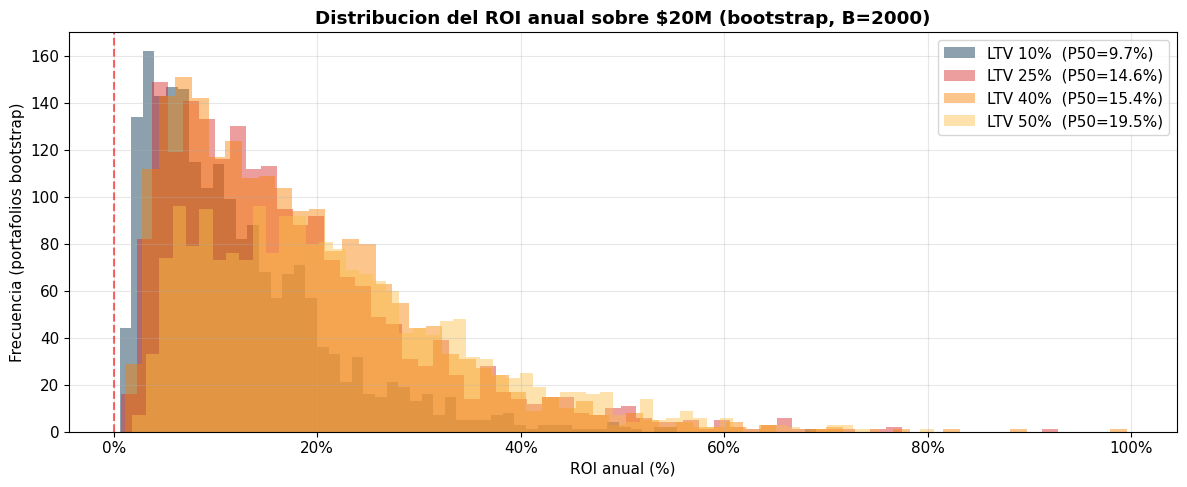


DISTRIBUCION DEL RETORNO ANUAL (P10 / P50 / P90)
  LTV 10% | ROI Y1 P10=3.0%  P50=9.7%  P90=23.7%  | P(perdida Y1) = 0.0%
  LTV 25% | ROI Y1 P10=4.7%  P50=14.6%  P90=34.3%  | P(perdida Y1) = 0.0%
  LTV 40% | ROI Y1 P10=5.1%  P50=15.4%  P90=33.6%  | P(perdida Y1) = 0.0%
  LTV 50% | ROI Y1 P10=6.9%  P50=19.5%  P90=40.2%  | P(perdida Y1) = 0.0%

LTV recomendado: 40%


In [ ]:
# ============================================================
# DISTRIBUCION DEL RETORNO ANUAL (BOOTSTRAP DE PORTAFOLIO)
# ============================================================
# Para cada LTV, simulamos B portafolios sinteticos con N=total_loans_year
# prestamos sampleados con reemplazo de results[ltv]. Reportamos P10/P50/P90
# del ROI anual sobre los $20M de capital.

B_BOOTSTRAP = 2000
np.random.seed(CONFIG["SEED"])

portfolio_dist = {}
composition = {}

for ltv in CONFIG["INIT_LTV_SCENARIOS"]:
    r = results[ltv]
    avg_p = r.original_principal.mean()
    avg_dur = r.duration_months.mean()

    max_concurrent = int(CAPITAL / avg_p)
    turnover = 12.0 / max(avg_dur, 1)
    total_loans_year = max(int(max_concurrent * turnover), 1)

    net_arr = r.net_income.values
    pnl_y1 = np.empty(B_BOOTSTRAP)
    pnl_y2 = np.empty(B_BOOTSTRAP)
    for b in range(B_BOOTSTRAP):
        sample = np.random.choice(net_arr, size=total_loans_year, replace=True)
        gross_year = sample.sum()
        pnl_y1[b] = gross_year - fc1
        pnl_y2[b] = gross_year - fc2

    roi_y1 = pnl_y1 / CAPITAL
    roi_y2 = pnl_y2 / CAPITAL

    portfolio_dist[ltv] = {
        "total_loans_year": total_loans_year,
        "pnl_y1_p10": float(np.percentile(pnl_y1, 10)),
        "pnl_y1_p50": float(np.percentile(pnl_y1, 50)),
        "pnl_y1_p90": float(np.percentile(pnl_y1, 90)),
        "roi_y1_p10": float(np.percentile(roi_y1, 10)),
        "roi_y1_p50": float(np.percentile(roi_y1, 50)),
        "roi_y1_p90": float(np.percentile(roi_y1, 90)),
        "roi_y2_p10": float(np.percentile(roi_y2, 10)),
        "roi_y2_p50": float(np.percentile(roi_y2, 50)),
        "roi_y2_p90": float(np.percentile(roi_y2, 90)),
        "prob_loss_y1": float((pnl_y1 < 0).mean()),
        "pnl_y1_samples": pnl_y1,
    }

    # --- Composicion del retorno por prestamo ---
    composition[ltv] = {
        "interest": float(r.interest_usd.mean()),
        "opening_fee": float(r.opening_fee_usd.mean()),
        "liq_fee": float(r.liq_fee_usd.mean()),
        "custody": float(r.custody_cost.mean()),
        "outgoing": float(r.outgoing_cost.mean()),
        "kyc": float(r.kyc_cost.mean()),
        "shortfall": float(r.shortfall_usd.mean()),
        "gross_income": float(r.gross_income_usd.mean()),
        "total_var_cost": float(r.total_var_cost.mean()),
        "net_income": float(r.net_income.mean()),
    }

# --- Grafica: distribucion del ROI anual por LTV ---
fig, ax = plt.subplots(figsize=(12, 5))
for i, ltv in enumerate(CONFIG["INIT_LTV_SCENARIOS"]):
    samples = portfolio_dist[ltv]["pnl_y1_samples"] / CAPITAL * 100
    ax.hist(samples, bins=60, alpha=0.45, color=colors[i],
            label=f'LTV {ltv*100:.0f}%  '
                  f'(P50={portfolio_dist[ltv]["roi_y1_p50"]*100:.1f}%)')
ax.axvline(x=0, color="red", linestyle="--", alpha=0.6)
ax.set_xlabel("ROI anual (%)")
ax.set_ylabel("Frecuencia (portafolios bootstrap)")
ax.set_title("Distribucion del ROI anual sobre $20M (bootstrap, B=2000)",
             fontweight="bold")
ax.legend()
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:.0f}%"))
plt.tight_layout()
fig.savefig(f"{IMG_DIR}/06_distribucion_roi.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Print resumen ---
print("\nDISTRIBUCION DEL RETORNO ANUAL (P10 / P50 / P90)")
print("=" * 70)
for ltv, pd_ in portfolio_dist.items():
    print(f"  LTV {ltv*100:.0f}% | "
          f"ROI Y1 P10={pd_['roi_y1_p10']*100:.1f}%  "
          f"P50={pd_['roi_y1_p50']*100:.1f}%  "
          f"P90={pd_['roi_y1_p90']*100:.1f}%  "
          f"| P(perdida Y1) = {pd_['prob_loss_y1']*100:.1f}%")

# --- LTV recomendado para el resumen ejecutivo ---
RECOMMENDED_LTV = 0.40
print(f"\nLTV recomendado: {RECOMMENDED_LTV*100:.0f}%")


In [ ]:
# ----- Generacion de reporte markdown -----
from generate_report import write_report

write_report(
    results=results,
    config=CONFIG,
    summary_df=summary_df,
    pnl_df=pnl_df,
    cost_rows=cost_rows,
    sensitivity_rows=sensitivity_rows,
    capital=CAPITAL,
    fc1=fc1,
    fc2=fc2,
    price_df=df,
    img_dir=IMG_DIR,
    pred_summaries=pred_summaries,
    vol_data=vol_data,
    buffer_results=buffer_results,
    reinvest_data={ltv: {'selffund_month': reinvest_data[ltv]['selffund_month'],
                          'pnl_60': reinvest_data[ltv]['proj'].iloc[-1]['P&L_acumulado']}
                   for ltv in reinvest_data},
    spread_data=spread_rows if 'spread_rows' in dir() else None,
    portfolio_dist=portfolio_dist,
    composition=composition,
    recommended_ltv=RECOMMENDED_LTV,
    accountant_view=accountant_view if 'accountant_view' in dir() else None,
)


# ----- Generacion de PDF -----
from generate_pdf import md_to_pdf
md_to_pdf('reporte_modelo_financiero.md', 'reporte_modelo_financiero.pdf')
